<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">NHL Opening &amp; Closing Odds, World Books — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 26,079 NHL games from the 2006-07 season to 31 October 2026, opening and closing prices from Pinnacle, Bet365,
William Hill, Bwin, Betway, Betfair Exchange, SBOBET and 1xBet, in decimal odds, each with the time it was recorded.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written in plain sight:
the README's and the listing's in the `CLAIMS` cell, the images' next to their check; everything else is read from the
data. Only what the file cannot show is not recomputed: the counts of prices left out while it was built (the 170
closing prices too far from the market and the others listed in the README), the 2 games recorded with home and away
reversed, the corrected start times of 2006-07 and 2007-08, and the 432 Pinnacle prices taken from a second record.

🏒 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/jytwci?utm_source=github&utm_medium=notebook&utm_campaign=nhl_world&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/nhl-opening-closing-odds-pinnacle-7-world-books-2006-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nhl_world&utm_content=whop_top) · free 20-game sample: same layout, same 194 columns.

## 0 · Setup

In [1]:
import os, glob, io, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
NAME = "NHL_World_Opening_Closing_Odds_2006-2026"

def find_csv():
    """The CSV of the full product (the largest match wins: sample and full may both be attached), or the CSV inside the ZIP."""
    hits = []
    for base in (os.environ.get("NHL_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.csv"), recursive=True) if os.path.isfile(p)]
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.zip"), recursive=True) if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError(NAME + ".csv not found: attach the full dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
if PATH.endswith(".zip"):
    data = zipfile.ZipFile(PATH).read(NAME + ".csv")
    RAW = pd.read_csv(io.BytesIO(data), dtype=str)
    F = pd.read_csv(io.BytesIO(data), low_memory=False)
else:
    RAW = pd.read_csv(PATH, dtype=str)                 # every cell exactly as written in the file
    F = pd.read_csv(PATH, low_memory=False)            # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

BOOKS = ["Pinnacle", "Bet365", "WilliamHill", "Bwin", "Betway", "BetfairExchange", "SBOBET", "1xBet"]
NAME_OF = {"WilliamHill": "William Hill", "BetfairExchange": "Betfair Exchange"}
ODDS = list(F.columns[18:])
PRICES = [c for c in ODDS if not c.endswith("_Time") and "_Line_" not in c]
LINES = [c for c in ODDS if "_Line_" in c]
KICK = pd.to_datetime(F["Kickoff_UTC"], utc=True)
DAY = F["Game_ID"].str[:8]
SEASONS = sorted(F["Season"].unique())

def ts(col):
    return pd.to_datetime(F[col], utc=True)

def minutes_vs_start(col):
    """Minutes between the recorded time and the scheduled start: negative = before."""
    return (ts(col) - KICK).dt.total_seconds() / 60

def no_vig(home, away):
    """Implied probability of the first side from two decimal prices, margin removed proportionally."""
    h, a = 1 / np.asarray(home, float), 1 / np.asarray(away, float)
    return h / (h + a)

def time_of(price_col):
    """The time column of a price column: Bwin_ML_Home_Close -> Bwin_ML_Close_Time."""
    p = price_col.split("_")
    return f"{p[0]}_{p[1]}_{p[-1]}_Time"

def cols(book, market):
    return [c for c in PRICES if c.startswith(f"{book}_{market}_")]

def priced(book, market=None):
    """Games with at least one price of this book (and market)."""
    cc = [c for c in PRICES if c.startswith(book + "_") and (market is None or c.split("_")[1] == market)]
    return F[cc].notna().any(axis=1)

def days(book, market=None):
    return sorted(DAY[priced(book, market)].unique())

def share(n, d):
    """Share in %, rounded down, written as in the README ('–' = none)."""
    return "–" if n == 0 else str(int(100 * n / d))

def short_age(m):
    """A median in minutes, written as in the README's closing-time table."""
    m = round(m)
    if m == 0:
        return "at the start"
    side = "after" if m > 0 else "before"
    return f"{abs(m)} min {side}" if abs(m) < 120 else f"{abs(m) / 60:.1f} h {side}"

def team(t):
    return (F["Home_Team"] == t) | (F["Away_Team"] == t)

RESULTS = []
def check(claim, ok, detail=""):
    ok = bool(ok)
    RESULTS.append((claim, ok, detail))
    print(f"{'PASS' if ok else 'FAIL'}  {claim}" + (f"   [{detail}]" if detail != "" else ""))

# Olivier Sports Data dark signature
BG, FG, FG2, GRID, CYAN, AMBER = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff", "#f5c86b"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": FG,
                     "axes.labelcolor": FG, "axes.edgecolor": GRID, "xtick.color": FG2, "ytick.color": FG2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlecolor": FG,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10, "legend.frameon": False})

NHL_World_Opening_Closing_Odds_2006-2026.csv  ·  26,079 rows  ·  194 columns


## 1 · The claims

Copied from the listing and the README shipped in the ZIP. Nothing below is adjusted to fit: if the file
disagrees, the cell prints FAIL.

In [2]:
def table(text, cols):
    """A table copied from the README: one row per season (or book), '–' = none."""
    out = {}
    for line in text.strip().splitlines():
        cells = [c.strip() for c in line.strip().strip("|").split("|")]
        out[cells[0]] = dict(zip(cols, cells[1:]))
    return out

CLAIMS = {
    "games": 26_079, "seasons": 21, "columns": 194, "game_columns": 18, "books": 8, "prices": 1_290_732,
    "first_day": "20061004", "last_day": "20261031", "games_2026_27": 226,
    "endings": {"Regulation": 20_073, "Overtime": 3_528, "Shootout": 2_478},
    "columns_per_book": {"Pinnacle": 22, "Bet365": 30, "WilliamHill": 14, "Bwin": 22, "Betway": 30,
                         "BetfairExchange": 14, "SBOBET": 14, "1xBet": 30},
    "markets": {"Pinnacle": "ML PuckLine Total", "Bet365": "ML PuckLine Total 1X2", "WilliamHill": "ML 1X2",
                "Bwin": "ML RegTotal 1X2", "Betway": "ML PuckLine Total 1X2", "BetfairExchange": "ML 1X2",
                "SBOBET": "ML RegTotal", "1xBet": "ML PuckLine RegTotal 1X2"},
    # listing: first price, book by book (the date of the Game_ID, US Eastern)
    "first_price": {"Bet365": "20061004", "Bwin": "20061004", "WilliamHill": "20061006", "Betway": "20070929",
                    "BetfairExchange": "20071201", "SBOBET": "20090319", "1xBet": "20141008", "Pinnacle": "20200801"},
    # README, said plainly: when each market starts and stops
    "market_days": {"WilliamHill ML": ("20090217", None), "WilliamHill 1X2": ("20061006", None),
                    "Betway 1X2": ("20070929", None), "Betway ML": ("20090129", None),
                    "BetfairExchange ML": ("20090211", None), "BetfairExchange 1X2": ("20071201", "20140611"),
                    "SBOBET RegTotal": ("20141008", "20220216"), "Bwin RegTotal": ("20111006", "20200311"),
                    "1xBet ML": ("20210120", None)},
    "ml_gaps": {"Bwin": ("20140130", "20141007"), "Betway": ("20150323", "20161011"),
                "BetfairExchange": ("20140612", "20160229"), "WilliamHill": ("20250618", "20260331")},
    "william_hill_back": "20260401",
    "sbobet_ml": ("20090319", "20140613", 5),                 # first day, last day of the run, games after it
    "onexbet_october_2014": ("1X2", "PuckLine", "RegTotal"),
    "no_price_games": 232, "no_price_nov_2007": (174, 185),   # 1 to 28 November 2007
    "pinnacle_first": "20200801", "no_pinnacle_ml": 469,
    "no_pinnacle_ml_split": {"Arizona": 311, "Utah HC 2024-25": 82, "2020 playoffs": 61, "others": 15},
    "no_pinnacle_ml_but": {"total": 309, "puck line": 145, "closing total": 48, "closing puck line": 19, "no price": 145},
    "bet365_pl_total": {"2012/2013": (21, 8), "from": "20171231", "2026/2027 closing": (203, 2)},
    "betway_pl_total": {"pl_one_game_2012_13": 1, "pl_back": "20241115", "total_2010_11_pct": 6, "total_back": "20241214"},
    "margin_close_median": {"BetfairExchange": "3.3", "Pinnacle": "2.5"},
    "median_open_age_h": {"Pinnacle": 29, "Bet365": 24, "WilliamHill": 27, "Bwin": 28, "Betway": 24,
                          "BetfairExchange": 24, "SBOBET": 24, "1xBet": 64},
    "oldest_opening_days": 14, "oldest_close_hours": 36, "every_change_close_hours": 12, "latest_close_minutes": 30,
    # README: prices that cannot exist were not used
    "limits": {"min_price": 1.01, "margin": (1, 12), "margin_exchange": (0, 6), "margin_1x2": (1, 20),
               "margin_1x2_exchange": (0, 8), "total_prices": (1.40, 3.50), "puckline_prices": (1.05, 6.00),
               "total_line": (3.5, 9.5)},
    "underdog_puckline_below": 0.42,
    # README, games
    "games_per_team": {"2012/2013": 48, "2020/2021": 56},
    "stop_2019_20": "20200311", "qualifying_and_round_robin": 44,
    "playoff_shootouts": ["20200803_WSH_TBL", "20200809_DAL_STL"],
    "names": {"ATL": ("Atlanta Thrashers", None, "2010/2011"), "WPG": ("Winnipeg Jets", "2011/2012", None),
              "PHX": ("Phoenix Coyotes", None, "2013/2014"), "ARI": ("Arizona Coyotes", "2014/2015", "2023/2024"),
              "UTA": (("Utah Hockey Club", "2024/2025"), ("Utah Mammoth", "2025/2026")),
              "VGK": ("Vegas Golden Knights", "2017/2018", None), "SEA": ("Seattle Kraken", "2021/2022", None)},
}
CLAIMS["games_table"] = table("""
| 2006/2007 | 1,230 | 81 | 1,311 |
| 2007/2008 | 1,230 | 85 | 1,315 |
| 2008/2009 | 1,230 | 87 | 1,317 |
| 2009/2010 | 1,230 | 89 | 1,319 |
| 2010/2011 | 1,230 | 89 | 1,319 |
| 2011/2012 | 1,230 | 86 | 1,316 |
| 2012/2013 | 720 | 86 | 806 |
| 2013/2014 | 1,230 | 93 | 1,323 |
| 2014/2015 | 1,230 | 89 | 1,319 |
| 2015/2016 | 1,230 | 91 | 1,321 |
| 2016/2017 | 1,230 | 87 | 1,317 |
| 2017/2018 | 1,271 | 84 | 1,355 |
| 2018/2019 | 1,271 | 87 | 1,358 |
| 2019/2020 | 1,082 | 130 | 1,212 |
| 2020/2021 | 868 | 84 | 952 |
| 2021/2022 | 1,312 | 89 | 1,401 |
| 2022/2023 | 1,312 | 88 | 1,400 |
| 2023/2024 | 1,312 | 88 | 1,400 |
| 2024/2025 | 1,312 | 86 | 1,398 |
| 2025/2026 | 1,312 | 82 | 1,394 |
| 2026/2027 | 226 | – | 226 |
""", ["Regular Season", "Playoffs", "Total"])
CLAIMS["median_close"] = table("""
| Pinnacle | 5 min after | 5 min after | 4 min after | – | – |
| Bet365 | 99 min before | 1 min after | 2 min after | – | 2.1 h before |
| WilliamHill | 3.2 h before | – | – | – | 2.7 h before |
| Bwin | 5.6 h before | – | – | 6.7 h before | 6.5 h before |
| Betway | 96 min before | 4.7 h before | 40 min before | – | 95 min before |
| BetfairExchange | 4 min before | – | – | – | 3 min before |
| SBOBET | 4.5 h before | – | – | 2.6 h before | – |
| 1xBet | 22 min before | 31 min before | – | 34 min before | 17 min before |
""", ["ML", "PuckLine", "Total", "RegTotal", "1X2"])
CLAIMS["totals_definition"] = table("""
| Pinnacle | Total | 2,436 | 50.2% | 49.2% | 42.1% |
| Bet365 | Total | 3,159 | 50.6% | 49.5% | 42.1% |
| Bwin | Total (regular time) | 1,610 | 49.7% | 55.3% | 47.6% |
| Betway | Total | 1,280 | 48.9% | 49.6% | 40.7% |
| SBOBET | Total (regular time) | 233 | 47.7% | 53.2% | 48.1% |
| 1xBet | Total (regular time) | 1,123 | 50.1% | 56.3% | 50.1% |
""", ["Column", "Games", "No-vig over", "Over final", "Over 60"])
CLAIMS["coverage"] = {
    ("ML_Home_Close", "Closing moneyline"): table("""
| 2006/2007 | – | – | – | – | – | – | – | – |
| 2007/2008 | – | – | – | – | – | – | – | – |
| 2008/2009 | – | 46 | 29 | 51 | 36 | 15 | 17 | – |
| 2009/2010 | – | 98 | 95 | 96 | 99 | 98 | 99 | – |
| 2010/2011 | – | 98 | 99 | 98 | 98 | 97 | 98 | – |
| 2011/2012 | – | 99 | 99 | 99 | 83 | 98 | 99 | – |
| 2012/2013 | – | 99 | 94 | 95 | 94 | 99 | 99 | – |
| 2013/2014 | – | 99 | 99 | 55 | 99 | 98 | 99 | – |
| 2014/2015 | – | 98 | 99 | 99 | 81 | – | – | – |
| 2015/2016 | – | 99 | 99 | 99 | – | 24 | – | – |
| 2016/2017 | – | 100 | 100 | 99 | 100 | 97 | – | – |
| 2017/2018 | – | 99 | 99 | 99 | 100 | 70 | – | – |
| 2018/2019 | – | 100 | 99 | 99 | 99 | 99 | 0 | – |
| 2019/2020 | 3 | 100 | 96 | 98 | 99 | 98 | – | – |
| 2020/2021 | 93 | 100 | 99 | 99 | 100 | 96 | – | 94 |
| 2021/2022 | 94 | 99 | 99 | 91 | 99 | 91 | – | 99 |
| 2022/2023 | 93 | 99 | 99 | 99 | 100 | 98 | – | 99 |
| 2023/2024 | 92 | 99 | 99 | 99 | 99 | 100 | – | 99 |
| 2024/2025 | 93 | 94 | 99 | 99 | 96 | 99 | – | 99 |
| 2025/2026 | 94 | 98 | 12 | 99 | 99 | 99 | – | – |
| 2026/2027 | 98 | 98 | 97 | 100 | 100 | 99 | – | 91 |
""", BOOKS),
    ("ML_Home_Open", "Opening moneyline"): table("""
| 2006/2007 | – | – | – | – | – | – | – | – |
| 2007/2008 | – | – | – | – | – | – | – | – |
| 2008/2009 | – | 26 | 6 | 21 | 8 | 7 | 9 | – |
| 2009/2010 | – | 73 | 47 | 49 | 36 | 18 | 74 | – |
| 2010/2011 | – | 81 | 72 | 53 | 56 | 0 | 78 | – |
| 2011/2012 | – | 84 | 72 | 75 | 54 | 0 | 86 | – |
| 2012/2013 | – | 79 | 49 | 86 | 60 | 0 | 84 | – |
| 2013/2014 | – | 80 | 53 | 49 | 73 | 0 | 84 | – |
| 2014/2015 | – | 80 | 80 | 67 | 61 | – | – | – |
| 2015/2016 | – | 81 | 77 | 70 | – | 0 | – | – |
| 2016/2017 | – | 85 | 84 | 66 | 85 | 15 | – | – |
| 2017/2018 | – | 81 | 79 | 53 | 81 | 16 | – | – |
| 2018/2019 | – | 84 | 79 | 62 | 81 | 17 | 0 | – |
| 2019/2020 | 3 | 83 | 75 | 58 | 79 | 45 | – | – |
| 2020/2021 | 93 | 83 | 81 | 62 | 81 | 7 | – | 86 |
| 2021/2022 | 94 | 83 | 86 | 65 | 86 | 15 | – | 90 |
| 2022/2023 | 94 | 82 | 82 | 73 | 71 | 24 | – | 94 |
| 2023/2024 | 94 | 76 | 83 | 76 | 70 | 27 | – | 93 |
| 2024/2025 | 93 | 63 | 85 | 82 | 70 | 41 | – | 94 |
| 2025/2026 | 99 | 83 | 10 | 81 | 71 | 13 | – | – |
| 2026/2027 | 98 | 82 | 76 | 71 | 69 | 33 | 1 | 97 |
""", BOOKS),
    ("PuckLine_Home_Close", "Closing puck line"): table("""
| 2006/2007 | – | – | – | – |
| 2007/2008 | – | – | – | – |
| 2008/2009 | – | 79 | 36 | – |
| 2009/2010 | – | 56 | 98 | – |
| 2010/2011 | – | 0 | 98 | – |
| 2011/2012 | – | 0 | 40 | – |
| 2012/2013 | – | 21 | 0 | – |
| 2013/2014 | – | – | – | – |
| 2014/2015 | – | – | – | 98 |
| 2015/2016 | – | – | – | 68 |
| 2016/2017 | – | – | – | 99 |
| 2017/2018 | – | 55 | – | 100 |
| 2018/2019 | – | 95 | – | 100 |
| 2019/2020 | 4 | 98 | – | 99 |
| 2020/2021 | 91 | 99 | – | 99 |
| 2021/2022 | 93 | 98 | – | 99 |
| 2022/2023 | 92 | 99 | – | 99 |
| 2023/2024 | 92 | 99 | – | 100 |
| 2024/2025 | 92 | 99 | 77 | 100 |
| 2025/2026 | 94 | 97 | 99 | 100 |
| 2026/2027 | 100 | 89 | 100 | 100 |
""", ["Pinnacle", "Bet365", "Betway", "1xBet"]),
    ("Total_Over_Close", "Closing total (overtime included)"): table("""
| 2006/2007 | – | – | – |
| 2007/2008 | – | – | – |
| 2008/2009 | – | 79 | 87 |
| 2009/2010 | – | 56 | 99 |
| 2010/2011 | – | 0 | 6 |
| 2011/2012 | – | 0 | – |
| 2012/2013 | – | 8 | – |
| 2013/2014 | – | – | – |
| 2014/2015 | – | – | – |
| 2015/2016 | – | – | – |
| 2016/2017 | – | – | – |
| 2017/2018 | – | 54 | – |
| 2018/2019 | – | 93 | – |
| 2019/2020 | 6 | 97 | – |
| 2020/2021 | 93 | 99 | – |
| 2021/2022 | 93 | 98 | – |
| 2022/2023 | 93 | 99 | – |
| 2023/2024 | 92 | 99 | – |
| 2024/2025 | 93 | 99 | 66 |
| 2025/2026 | 92 | 97 | 99 |
| 2026/2027 | 99 | 0 | 100 |
""", ["Pinnacle", "Bet365", "Betway"]),
    ("RegTotal_Over_Close", "Closing total (regular time)"): table("""
| 2006/2007 | – | – | – |
| 2007/2008 | – | – | – |
| 2008/2009 | – | – | – |
| 2009/2010 | – | – | – |
| 2010/2011 | – | – | – |
| 2011/2012 | 97 | – | – |
| 2012/2013 | 97 | – | – |
| 2013/2014 | 97 | – | – |
| 2014/2015 | 98 | 99 | 97 |
| 2015/2016 | 99 | 100 | 68 |
| 2016/2017 | 99 | 100 | 99 |
| 2017/2018 | 99 | 100 | 99 |
| 2018/2019 | 98 | 99 | 99 |
| 2019/2020 | 88 | 99 | 99 |
| 2020/2021 | – | 99 | 100 |
| 2021/2022 | – | 54 | 99 |
| 2022/2023 | – | – | 99 |
| 2023/2024 | – | – | 100 |
| 2024/2025 | – | – | 100 |
| 2025/2026 | – | – | 100 |
| 2026/2027 | – | – | 100 |
""", ["Bwin", "SBOBET", "1xBet"]),
    ("1X2_Home_Close", "Closing 1X2 (regular time)"): table("""
| 2006/2007 | 54 | 91 | 73 | – | – | – |
| 2007/2008 | 42 | 3 | 85 | 84 | 5 | – |
| 2008/2009 | 94 | 41 | 69 | 92 | 48 | – |
| 2009/2010 | 98 | 93 | 94 | 99 | 98 | – |
| 2010/2011 | 99 | 98 | 94 | 98 | 97 | – |
| 2011/2012 | 100 | – | 98 | 95 | 98 | – |
| 2012/2013 | 99 | 18 | 96 | 94 | 45 | – |
| 2013/2014 | 99 | 96 | 98 | 99 | 98 | – |
| 2014/2015 | 98 | 97 | 99 | 99 | – | 99 |
| 2015/2016 | 100 | 99 | 99 | 99 | – | 68 |
| 2016/2017 | 100 | 99 | 99 | 100 | – | 99 |
| 2017/2018 | 100 | 99 | 99 | 100 | – | 99 |
| 2018/2019 | 100 | 99 | 99 | 99 | – | 99 |
| 2019/2020 | 100 | 96 | 99 | 99 | – | 99 |
| 2020/2021 | 99 | 99 | 99 | 100 | – | 100 |
| 2021/2022 | 99 | 99 | 90 | 99 | – | 99 |
| 2022/2023 | 99 | 99 | 98 | 100 | – | 99 |
| 2023/2024 | 99 | 99 | 99 | 99 | – | 100 |
| 2024/2025 | 94 | 99 | 99 | 96 | – | 100 |
| 2025/2026 | 99 | 14 | 99 | 99 | – | 100 |
| 2026/2027 | 99 | 100 | 100 | 100 | – | 100 |
""", ["Bet365", "WilliamHill", "Bwin", "Betway", "BetfairExchange", "1xBet"]),
    ("PuckLine_Home_Open", "Opening puck line"): table("""
| 2006/2007 | – | – | – | – |
| 2007/2008 | – | – | – | – |
| 2008/2009 | – | 13 | 5 | – |
| 2009/2010 | – | 25 | 21 | – |
| 2010/2011 | – | 0 | 45 | – |
| 2011/2012 | – | 0 | 19 | – |
| 2012/2013 | – | 16 | – | – |
| 2013/2014 | – | – | – | – |
| 2014/2015 | – | – | – | 85 |
| 2015/2016 | – | – | – | 63 |
| 2016/2017 | – | – | – | 92 |
| 2017/2018 | – | 55 | – | 54 |
| 2018/2019 | – | 97 | – | 44 |
| 2019/2020 | 5 | 98 | – | 71 |
| 2020/2021 | 93 | 99 | – | 23 |
| 2021/2022 | 94 | 98 | – | 11 |
| 2022/2023 | 93 | 99 | – | 10 |
| 2023/2024 | 98 | 97 | – | 11 |
| 2024/2025 | 98 | 98 | 64 | 45 |
| 2025/2026 | 100 | 98 | 79 | 77 |
| 2026/2027 | 100 | 91 | 74 | 89 |
""", ["Pinnacle", "Bet365", "Betway", "1xBet"]),
    ("Total_Over_Open", "Opening total (overtime included)"): table("""
| 2006/2007 | – | – | – |
| 2007/2008 | – | – | – |
| 2008/2009 | – | 47 | 28 |
| 2009/2010 | – | 39 | 28 |
| 2010/2011 | – | 0 | 2 |
| 2011/2012 | – | 0 | – |
| 2012/2013 | – | 5 | – |
| 2013/2014 | – | – | – |
| 2014/2015 | – | – | – |
| 2015/2016 | – | – | – |
| 2016/2017 | – | – | – |
| 2017/2018 | – | 54 | – |
| 2018/2019 | – | 96 | – |
| 2019/2020 | 6 | 98 | – |
| 2020/2021 | 95 | 98 | – |
| 2021/2022 | 98 | 98 | – |
| 2022/2023 | 98 | 99 | – |
| 2023/2024 | 98 | 97 | – |
| 2024/2025 | 98 | 98 | 50 |
| 2025/2026 | 99 | 97 | 71 |
| 2026/2027 | 100 | – | 67 |
""", ["Pinnacle", "Bet365", "Betway"]),
    ("RegTotal_Over_Open", "Opening total (regular time)"): table("""
| 2006/2007 | – | – | – |
| 2007/2008 | – | – | – |
| 2008/2009 | – | – | – |
| 2009/2010 | – | – | – |
| 2010/2011 | – | – | – |
| 2011/2012 | 56 | – | – |
| 2012/2013 | 77 | – | – |
| 2013/2014 | 82 | – | – |
| 2014/2015 | 56 | 84 | 91 |
| 2015/2016 | 63 | 85 | 65 |
| 2016/2017 | 46 | 87 | 95 |
| 2017/2018 | 28 | 84 | 95 |
| 2018/2019 | 31 | 87 | 96 |
| 2019/2020 | 26 | 78 | 95 |
| 2020/2021 | – | 69 | 90 |
| 2021/2022 | – | 39 | 91 |
| 2022/2023 | – | – | 95 |
| 2023/2024 | – | – | 95 |
| 2024/2025 | – | – | 96 |
| 2025/2026 | – | – | 96 |
| 2026/2027 | – | – | 96 |
""", ["Bwin", "SBOBET", "1xBet"]),
}
print(f"{sum(len(v) for v in CLAIMS['coverage'].values())} coverage rows, {len(CLAIMS)} claims blocks, copied from the README")

189 coverage rows, 43 claims blocks, copied from the README


## 2 · The file

One CSV, one row per game. For each book and market: the opening price, then the closing price, each with the time
it was recorded. Decimal odds.

In [3]:
check(f"{CLAIMS['games']:,} games, one row each: Game_ID and NHL_Game_ID unique", len(F) == CLAIMS["games"] and F["Game_ID"].is_unique
      and F["NHL_Game_ID"].is_unique, f"{len(F):,}")
check(f"{CLAIMS['columns']} columns: {CLAIMS['game_columns']} for the game, then the books",
      F.shape[1] == CLAIMS["columns"] and len(ODDS) == CLAIMS["columns"] - CLAIMS["game_columns"], f"{F.shape[1]}")
found = list(dict.fromkeys(c.split("_")[0] for c in ODDS))
check(f"{CLAIMS['books']} books, in this order: " + ", ".join(NAME_OF.get(b, b) for b in BOOKS), found == BOOKS, ", ".join(found))
order_ok = all(max(i for i, c in enumerate(ODDS) if c.startswith(b + "_") and "_Open" in c)
               < min(i for i, c in enumerate(ODDS) if c.startswith(b + "_") and "_Close" in c) for b in BOOKS)
check("for each book, its opening columns come first, then its closing columns", order_ok)
per = {b: sum(c.startswith(b + "_") for c in ODDS) for b in BOOKS}
check("columns per book, as in the README: Pinnacle 22, Bet365 30, William Hill 14, Bwin 22, Betway 30, Betfair Exchange 14, SBOBET 14, 1xBet 30",
      per == CLAIMS["columns_per_book"], " · ".join(f"{NAME_OF.get(b, b)} {n}" for b, n in per.items()))
mk = {b: " ".join(dict.fromkeys(c.split("_")[1] for c in ODDS if c.startswith(b + "_"))) for b in BOOKS}
check("markets per book, as in the README (Total = overtime included, RegTotal = regular time)", mk == CLAIMS["markets"], f"{mk}")
cells = pd.Series(RAW[PRICES].to_numpy().ravel()).dropna()
check(f"{CLAIMS['prices']:,} prices", len(cells) == CLAIMS["prices"], f"{len(cells):,}")
check(f"every price is a decimal price of at least {CLAIMS['limits']['min_price']}, with up to 4 decimals",
      cells.str.fullmatch(r"\d+(\.\d{1,4})?").all() and (cells.astype(float) >= CLAIMS["limits"]["min_price"]).all(),
      f"lowest {cells.astype(float).min()}, highest {cells.astype(float).max()}")
untimed = sum(int((F[c].notna() & F[time_of(c)].isna()).sum()) for c in PRICES)
check("every price comes with the time it was recorded", untimed == 0, f"{untimed} without a time")
times = pd.Series(RAW[[c for c in ODDS if c.endswith("_Time")] + ["Kickoff_UTC"]].to_numpy().ravel()).dropna()
check("every time is ISO 8601 in UTC, with the T and the Z", times.str.fullmatch(r"\d{4}-\d\d-\d\dT\d\d:\d\d:\d\dZ").all(),
      f"{len(times):,} cells")
check("Epoch is the scheduled start in Unix seconds", (pd.to_datetime(F["Epoch"], unit="s", utc=True) == KICK).all())
away_code, home_code = F["Game_ID"].str[9:12], F["Game_ID"].str[13:16]
codes = pd.concat([pd.DataFrame({"Season": F["Season"], "Team": F["Home_Team"], "Code": home_code}),
                   pd.DataFrame({"Season": F["Season"], "Team": F["Away_Team"], "Code": away_code})])
one_code = codes.groupby(["Season", "Team"])["Code"].nunique().max() == 1
check("Game_ID reads YYYYMMDD_AWAY_HOME: the date in US Eastern time, then the away team's code, then the home team's",
      RAW["Game_ID"].str.fullmatch(r"\d{8}_[A-Z]{3}_[A-Z]{3}").all() and one_code
      and (KICK.dt.tz_convert("America/New_York").dt.strftime("%Y%m%d") == DAY).all())
check("NHL_Game_ID: season, game type (02 regular season, 03 playoffs), game number",
      (RAW["NHL_Game_ID"].str[:4] == F["Season"].str[:4]).all()
      and ((RAW["NHL_Game_ID"].str[4:6] == "02") == (F["Stage"] == "Regular Season")).all()
      and ((RAW["NHL_Game_ID"].str[4:6] == "03") == (F["Stage"] == "Playoffs")).all())
nm = CLAIMS["names"]
def seasons_of(code, name):
    return sorted(codes.loc[(codes["Code"] == code) & (codes["Team"] == name), "Season"].unique())
ok_names = True
for code_, spec in nm.items():
    if code_ == "UTA":
        (n1, s1), (n2, s2) = spec
        ok_names &= seasons_of("UTA", n1) == [s1] and seasons_of("UTA", n2)[0] == s2
        continue
    name_, first_, last_ = spec
    s = seasons_of(code_, name_)
    ok_names &= bool(s) and (first_ is None or s[0] == first_) and (last_ is None or s[-1] == last_)
    ok_names &= set(codes.loc[codes["Team"] == name_, "Code"]) == {code_}
check("team names follow the season: Atlanta Thrashers to 2010-11, then Winnipeg Jets; Phoenix Coyotes to 2013-14, then Arizona "
      "Coyotes to 2023-24; Utah Hockey Club in 2024-25, then Utah Mammoth (UTA for both); Vegas from 2017-18, Seattle from 2021-22", ok_names)

PASS  26,079 games, one row each: Game_ID and NHL_Game_ID unique   [26,079]
PASS  194 columns: 18 for the game, then the books   [194]
PASS  8 books, in this order: Pinnacle, Bet365, William Hill, Bwin, Betway, Betfair Exchange, SBOBET, 1xBet   [Pinnacle, Bet365, WilliamHill, Bwin, Betway, BetfairExchange, SBOBET, 1xBet]
PASS  for each book, its opening columns come first, then its closing columns
PASS  columns per book, as in the README: Pinnacle 22, Bet365 30, William Hill 14, Bwin 22, Betway 30, Betfair Exchange 14, SBOBET 14, 1xBet 30   [Pinnacle 22 · Bet365 30 · William Hill 14 · Bwin 22 · Betway 30 · Betfair Exchange 14 · SBOBET 14 · 1xBet 30]
PASS  markets per book, as in the README (Total = overtime included, RegTotal = regular time)   [{'Pinnacle': 'ML PuckLine Total', 'Bet365': 'ML PuckLine Total 1X2', 'WilliamHill': 'ML 1X2', 'Bwin': 'ML RegTotal 1X2', 'Betway': 'ML PuckLine Total 1X2', 'BetfairExchange': 'ML 1X2', 'SBOBET': 'ML RegTotal', '1xBet': 'ML PuckLine RegTotal 1X2'

PASS  1,290,732 prices   [1,290,732]


PASS  every price is a decimal price of at least 1.01, with up to 4 decimals   [lowest 1.14, highest 21.0]
PASS  every price comes with the time it was recorded   [0 without a time]


PASS  every time is ISO 8601 in UTC, with the T and the Z   [589,732 cells]
PASS  Epoch is the scheduled start in Unix seconds


PASS  Game_ID reads YYYYMMDD_AWAY_HOME: the date in US Eastern time, then the away team's code, then the home team's
PASS  NHL_Game_ID: season, game type (02 regular season, 03 playoffs), game number
PASS  team names follow the season: Atlanta Thrashers to 2010-11, then Winnipeg Jets; Phoenix Coyotes to 2013-14, then Arizona Coyotes to 2023-24; Utah Hockey Club in 2024-25, then Utah Mammoth (UTA for both); Vegas from 2017-18, Seattle from 2021-22


### Prices that cannot exist

The README lists the prices that were not used: margins out of bounds, puck lines other than ±1.5, total lines
outside 3.5-9.5 goals or not a multiple of 0.25, prices outside their range. Recomputed on every price left in the file.

In [4]:
Lm = CLAIMS["limits"]
def values(cc):
    """Every non-empty cell of these columns, as one series."""
    return pd.Series(F[cc].to_numpy().ravel()).dropna()
pl_l = values([c for c in LINES if "_PuckLine_" in c])
tot_l = values([c for c in LINES if "_Total_" in c])
check("puck line: ±1.5 only", set(pl_l.unique()) <= {-1.5, 1.5}, sorted(pl_l.unique()))
check(f"total lines between {Lm['total_line'][0]} and {Lm['total_line'][1]} goals, multiples of 0.25",
      tot_l.between(*Lm["total_line"]).all() and ((tot_l * 4) % 1 == 0).all(), f"{tot_l.min()} to {tot_l.max()}")
tp = values([c for c in PRICES if "_Total_" in c])
pp = values([c for c in PRICES if "_PuckLine_" in c])
check(f"total prices between {Lm['total_prices'][0]:.2f} and {Lm['total_prices'][1]:.2f}, puck line prices between "
      f"{Lm['puckline_prices'][0]:.2f} and {Lm['puckline_prices'][1]:.2f}",
      tp.between(*Lm["total_prices"]).all() and pp.between(*Lm["puckline_prices"]).all(),
      f"totals {tp.min()} to {tp.max()} · puck lines {pp.min()} to {pp.max()}")

SIDES = {"ML": ("Home", "Away"), "PuckLine": ("Home", "Away"), "Total": ("Over", "Under"), "RegTotal": ("Over", "Under"),
         "1X2": ("Home", "Draw", "Away")}
def margins(book, market, phase):
    cc = [f"{book}_{market}_{s}_{phase}" for s in SIDES[market]]
    if cc[0] not in F:
        return pd.Series(dtype=float)
    x = F[cc].dropna()
    return 100 * ((1 / x).sum(axis=1) - 1)

bad, rows = [], []
for b in BOOKS:
    for m in SIDES:
        for ph in ("Open", "Close"):
            mg = margins(b, m, ph)
            if mg.empty:
                continue
            if m == "1X2":
                lo, hi = Lm["margin_1x2_exchange"] if b == "BetfairExchange" else Lm["margin_1x2"]
            else:
                lo, hi = Lm["margin_exchange"] if b == "BetfairExchange" else Lm["margin"]
            out = int((~mg.between(lo, hi)).sum())
            rows.append((NAME_OF.get(b, b), m, ph, len(mg), round(mg.min(), 2), round(mg.median(), 2), round(mg.max(), 2)))
            if out:
                bad.append(f"{b} {m} {ph}: {out}")
check("every two-way market has a margin of 1-12% (Betfair Exchange 0-6%), every 1X2 1-20% (Betfair Exchange 0-8%)", not bad, ", ".join(bad[:6]))
pd.DataFrame(rows, columns=["Book", "Market", "Phase", "Markets", "Min %", "Median %", "Max %"]).set_index(["Book", "Market", "Phase"])

PASS  puck line: ±1.5 only   [[np.float64(-1.5), np.float64(1.5)]]
PASS  total lines between 3.5 and 9.5 goals, multiples of 0.25   [4.5 to 7.5]
PASS  total prices between 1.40 and 3.50, puck line prices between 1.05 and 6.00   [totals 1.4 to 2.85 · puck lines 1.14 to 5.8]
PASS  every two-way market has a margin of 1-12% (Betfair Exchange 0-6%), every 1X2 1-20% (Betfair Exchange 0-8%)


Markets  Min %  Median %  Max %
Book             Market   Phase                                 
Pinnacle         ML       Open      7812   2.29      3.01   5.80
                          Close     7704   2.17      2.54   4.45
                 PuckLine Open      7956   2.35      3.21   6.90
                          Close     7677   2.25      2.69   5.02
                 Total    Open      8103   2.73      3.38   5.39
                          Close     7704   2.70      2.91   4.81
Bet365           ML       Open     18148   1.03      3.98   7.53
                          Close    22583   1.15      4.10   8.10
                 PuckLine Open     11939   1.03      4.11   7.97
                          Close    13282   1.75      4.11   9.03
                 Total    Open     12237   1.01      4.56   9.29
                          Close    12921   1.01      4.56   9.29
                 1X2      Open      7768   3.02      6.66  12.64
                          Close    24482   3.90      6.77  17.75
William Hill     ML       Open     15847   1.55      3.93   8.66
                          Close    21090   1.35      3.93   8.52
                 1X2      Open      5817   5.13      9.29  14.39
                          Close    20515   3.68      9.55  16.92
Bwin             ML       Open     15027   1.01      4.53  11.41
                          Close    21913   1.59      4.56  11.46
                 RegTotal Open      5777   3.19      4.65   5.34
                          Close    11056   1.95      4.65   8.42
                 1X2      Open     10497   5.22      7.98  13.82
                          Close    24727   3.51      7.87  17.99
Betway           ML       Open     14748   1.56      4.44  11.90
                          Close    20687   1.72      4.56  10.63
                 PuckLine Open      3386   3.19      6.67   9.29
                          Close     6315   2.67      4.73   8.82
                 Total    Open      2643   1.16      4.64   8.11
                          Close     5090   3.17      4.71   8.33
                 1X2      Open      9200   4.12      8.61  12.62
                          Close    24246   3.62      8.35  13.93
Betfair Exchange ML       Open      3461   0.08      4.33   6.00
                          Close    19258   1.58      3.35   5.99
                 1X2      Open       298   0.04      3.98   7.99
                          Close     6254   2.81      4.85   7.95
SBOBET           ML       Open      5078   1.84      3.97   9.15
                          Close     6287   1.59      4.01   7.37
                 RegTotal Open      7902   3.10      3.76   9.34
                          Close     9592   3.12      3.85   9.62
1xBet            ML       Open      6266   1.22      1.55   3.32
                          Close     6701   1.16      1.56   5.02
                 PuckLine Open      8004   1.07      2.20  10.54
                          Close    15615   1.02      2.10  11.82
                 RegTotal Open     14824   1.01      3.63   8.70
                          Close    15594   1.01      3.73   9.94
                 1X2      Open     13994   1.04      3.11  10.40
                          Close    15628   1.01      4.41  15.66

## 3 · Games

The NHL's official record: games, final scores, the score after 60 minutes, how each game ended.

In [5]:
st = pd.crosstab(F["Season"], F["Stage"]).reindex(columns=["Regular Season", "Playoffs"], fill_value=0)
st["Total"] = st.sum(axis=1)
as_written = {s: {c: ("–" if v == 0 else f"{v:,}") for c, v in r.items()} for s, r in st.astype(int).to_dict("index").items()}
check(f"{CLAIMS['seasons']} seasons, games per season and stage as in the README", as_written == CLAIMS["games_table"],
      " · ".join(f"{s[2:4]}-{s[-2:]} {n:,}" for s, n in st["Total"].items()))
check(f"first game on 4 Oct 2006, last on 31 Oct 2026, {CLAIMS['games_2026_27']} games of 2026-27",
      (DAY.min(), DAY.max()) == (CLAIMS["first_day"], CLAIMS["last_day"]) and (F["Season"] == "2026/2027").sum() == CLAIMS["games_2026_27"],
      f"{F['Game_ID'].iloc[0]} to {F['Game_ID'].iloc[-1]}")
ends = F["Match_Ending"].value_counts().to_dict()
check("3,528 games decided in overtime, 2,478 in a shootout", ends == CLAIMS["endings"], f"{ends}")
hs, aw = F["Home_Score"], F["Away_Score"]
check("Winner, Total_Score and Margin agree with the score on every game",
      ((F["Winner"] == "Home") == (hs > aw)).all() and (hs != aw).all() and (hs + aw == F["Total_Score"]).all()
      and ((hs - aw).abs() == F["Margin"]).all())
tied60 = F["Home_Score_60"] == F["Away_Score_60"]
r60 = np.select([F["Home_Score_60"] > F["Away_Score_60"], tied60], ["Home", "Draw"], "Away")
check("Result_60 follows the score after 60 minutes; overtime and shootout games, and only they, were tied after 60",
      (F["Result_60"] == r60).all() and (tied60 == (F["Match_Ending"] != "Regulation")).all())
check("a game decided in overtime or a shootout: tied after 60 minutes at the loser's final score, won by exactly one goal",
      (np.minimum(hs, aw)[tied60] == F.loc[tied60, "Home_Score_60"]).all() and ((hs - aw).abs()[tied60] == 1).all()
      and ((F["Home_Score_60"] == hs) & (F["Away_Score_60"] == aw))[~tied60].all())
rs = F[F["Stage"] == "Regular Season"]
per_team = {s: pd.concat([x["Home_Team"], x["Away_Team"]]).value_counts() for s, x in rs.groupby("Season")}
check("the 48-game lockout season 2012-13 and the 56-game season 2020-21: every team's regular-season games",
      all((per_team[s] == n).all() for s, n in CLAIMS["games_per_team"].items()),
      " · ".join(f"{s[2:4]}-{s[-2:]} {sorted(set(per_team[s]))}" for s in CLAIMS["games_per_team"]))
s20 = F["Season"] == "2019/2020"
po20 = s20 & (F["Stage"] == "Playoffs")
qual = po20 & (RAW["NHL_Game_ID"].str[6:8] == "00")
check("2019-20: the regular season stops on 11 Mar 2020; its playoffs include the 44 games of the August 2020 qualifying round and round-robin",
      DAY[s20 & (F["Stage"] == "Regular Season")].max() == CLAIMS["stop_2019_20"] and qual.sum() == CLAIMS["qualifying_and_round_robin"]
      and DAY[qual].str[:6].unique().tolist() == ["202008"], f"{int(qual.sum())} games")
pso = F.loc[(F["Stage"] == "Playoffs") & (F["Match_Ending"] == "Shootout"), "Game_ID"].tolist()
check("two round-robin games ended in a shootout (Washington at Tampa Bay, 3 Aug; Dallas at St. Louis, 9 Aug 2020), the only playoff shootouts",
      pso == CLAIMS["playoff_shootouts"], f"{pso}")

PASS  21 seasons, games per season and stage as in the README   [06-07 1,311 · 07-08 1,315 · 08-09 1,317 · 09-10 1,319 · 10-11 1,319 · 11-12 1,316 · 12-13 806 · 13-14 1,323 · 14-15 1,319 · 15-16 1,321 · 16-17 1,317 · 17-18 1,355 · 18-19 1,358 · 19-20 1,212 · 20-21 952 · 21-22 1,401 · 22-23 1,400 · 23-24 1,400 · 24-25 1,398 · 25-26 1,394 · 26-27 226]
PASS  first game on 4 Oct 2006, last on 31 Oct 2026, 226 games of 2026-27   [20061004_BUF_CAR to 20261031_CGY_COL]
PASS  3,528 games decided in overtime, 2,478 in a shootout   [{'Regulation': 20073, 'Overtime': 3528, 'Shootout': 2478}]
PASS  Winner, Total_Score and Margin agree with the score on every game
PASS  Result_60 follows the score after 60 minutes; overtime and shootout games, and only they, were tied after 60
PASS  a game decided in overtime or a shootout: tied after 60 minutes at the loser's final score, won by exactly one goal
PASS  the 48-game lockout season 2012-13 and the 56-game season 2020-21: every team's regular-season ga

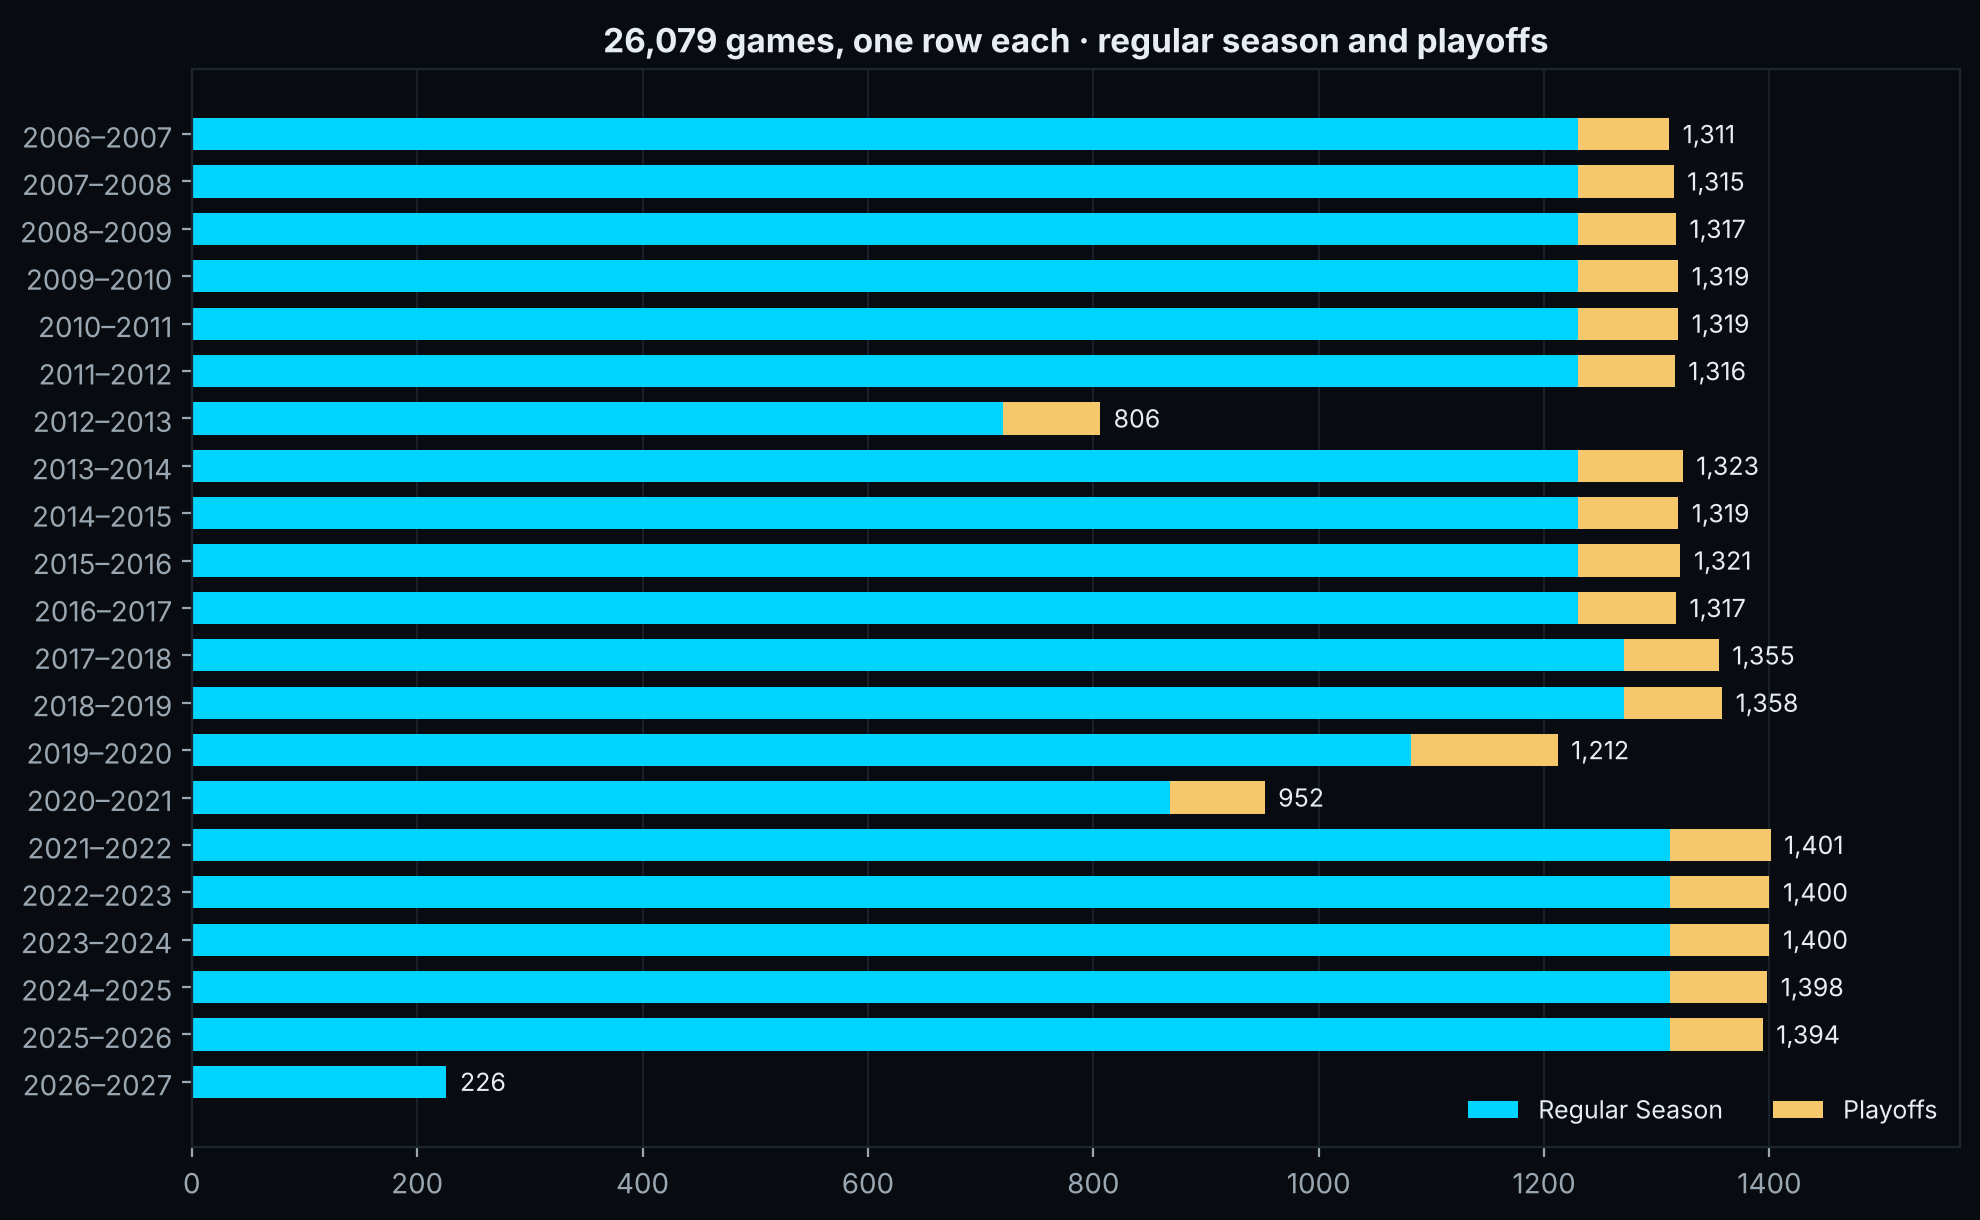

In [6]:
st = pd.crosstab(F["Season"], F["Stage"]).reindex(columns=["Regular Season", "Playoffs"], fill_value=0)
fig, ax = plt.subplots(figsize=(10, 6.2))
left = np.zeros(len(st))
colors = {"Regular Season": CYAN, "Playoffs": AMBER}
for stage in st.columns:
    ax.barh(range(len(st)), st[stage], left=left, color=colors[stage], height=0.68, label=stage, zorder=2)
    left += st[stage].to_numpy()
for i, total in enumerate(left):
    ax.text(total + 12, i, f"{int(total):,}", va="center", fontsize=9, color=FG)
ax.set_yticks(range(len(st)), [s.replace("/", "–") for s in st.index])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, left.max() * 1.12)
ax.legend(loc="lower right", ncol=2, fontsize=9)
ax.set_title(f"{len(F):,} games, one row each · regular season and playoffs")
plt.tight_layout(); plt.show()

## 4 · Who is in the file, and from when

The listing gives the first price of each book; the README gives the share of games covered, season by season,
for every book, market and phase. Recomputed here from the price columns.

PASS  first price, book by book, as listed: Bet365 and Bwin 4 Oct 2006 ... Pinnacle 1 Aug 2020   [Pinnacle 20200801 · Bet365 20061004 · William Hill 20061006 · Bwin 20061004 · Betway 20070929 · Betfair Exchange 20071201 · SBOBET 20090319 · 1xBet 20141008]
PASS  2006-07 and 2007-08 carry the 1X2 only; the moneyline starts in 2008-09
PASS  first (and last) day of each market, as in the README: William Hill's moneyline from 17 Feb 2009 and 1X2 from 6 Oct 2006, Betway's 1X2 from 29 Sep 2007 and moneyline from 29 Jan 2009, Betfair Exchange's moneyline from 11 Feb 2009 and 1X2 from 1 Dec 2007 to 11 Jun 2014, Bwin's regular-time total 6 Oct 2011 to 11 Mar 2020, SBOBET's 8 Oct 2014 to 16 Feb 2022, 1xBet's moneyline from 20 Jan 2021   [{}]
PASS  1xBet's 1X2, puck line and regular-time total start in October 2014; no 1xBet moneyline in 2025-26   [{'1X2': '201410', 'PuckLine': '201410', 'RegTotal': '201410'}]
PASS  Closing moneyline: share of games, season by season, as in the README (21 seasons 

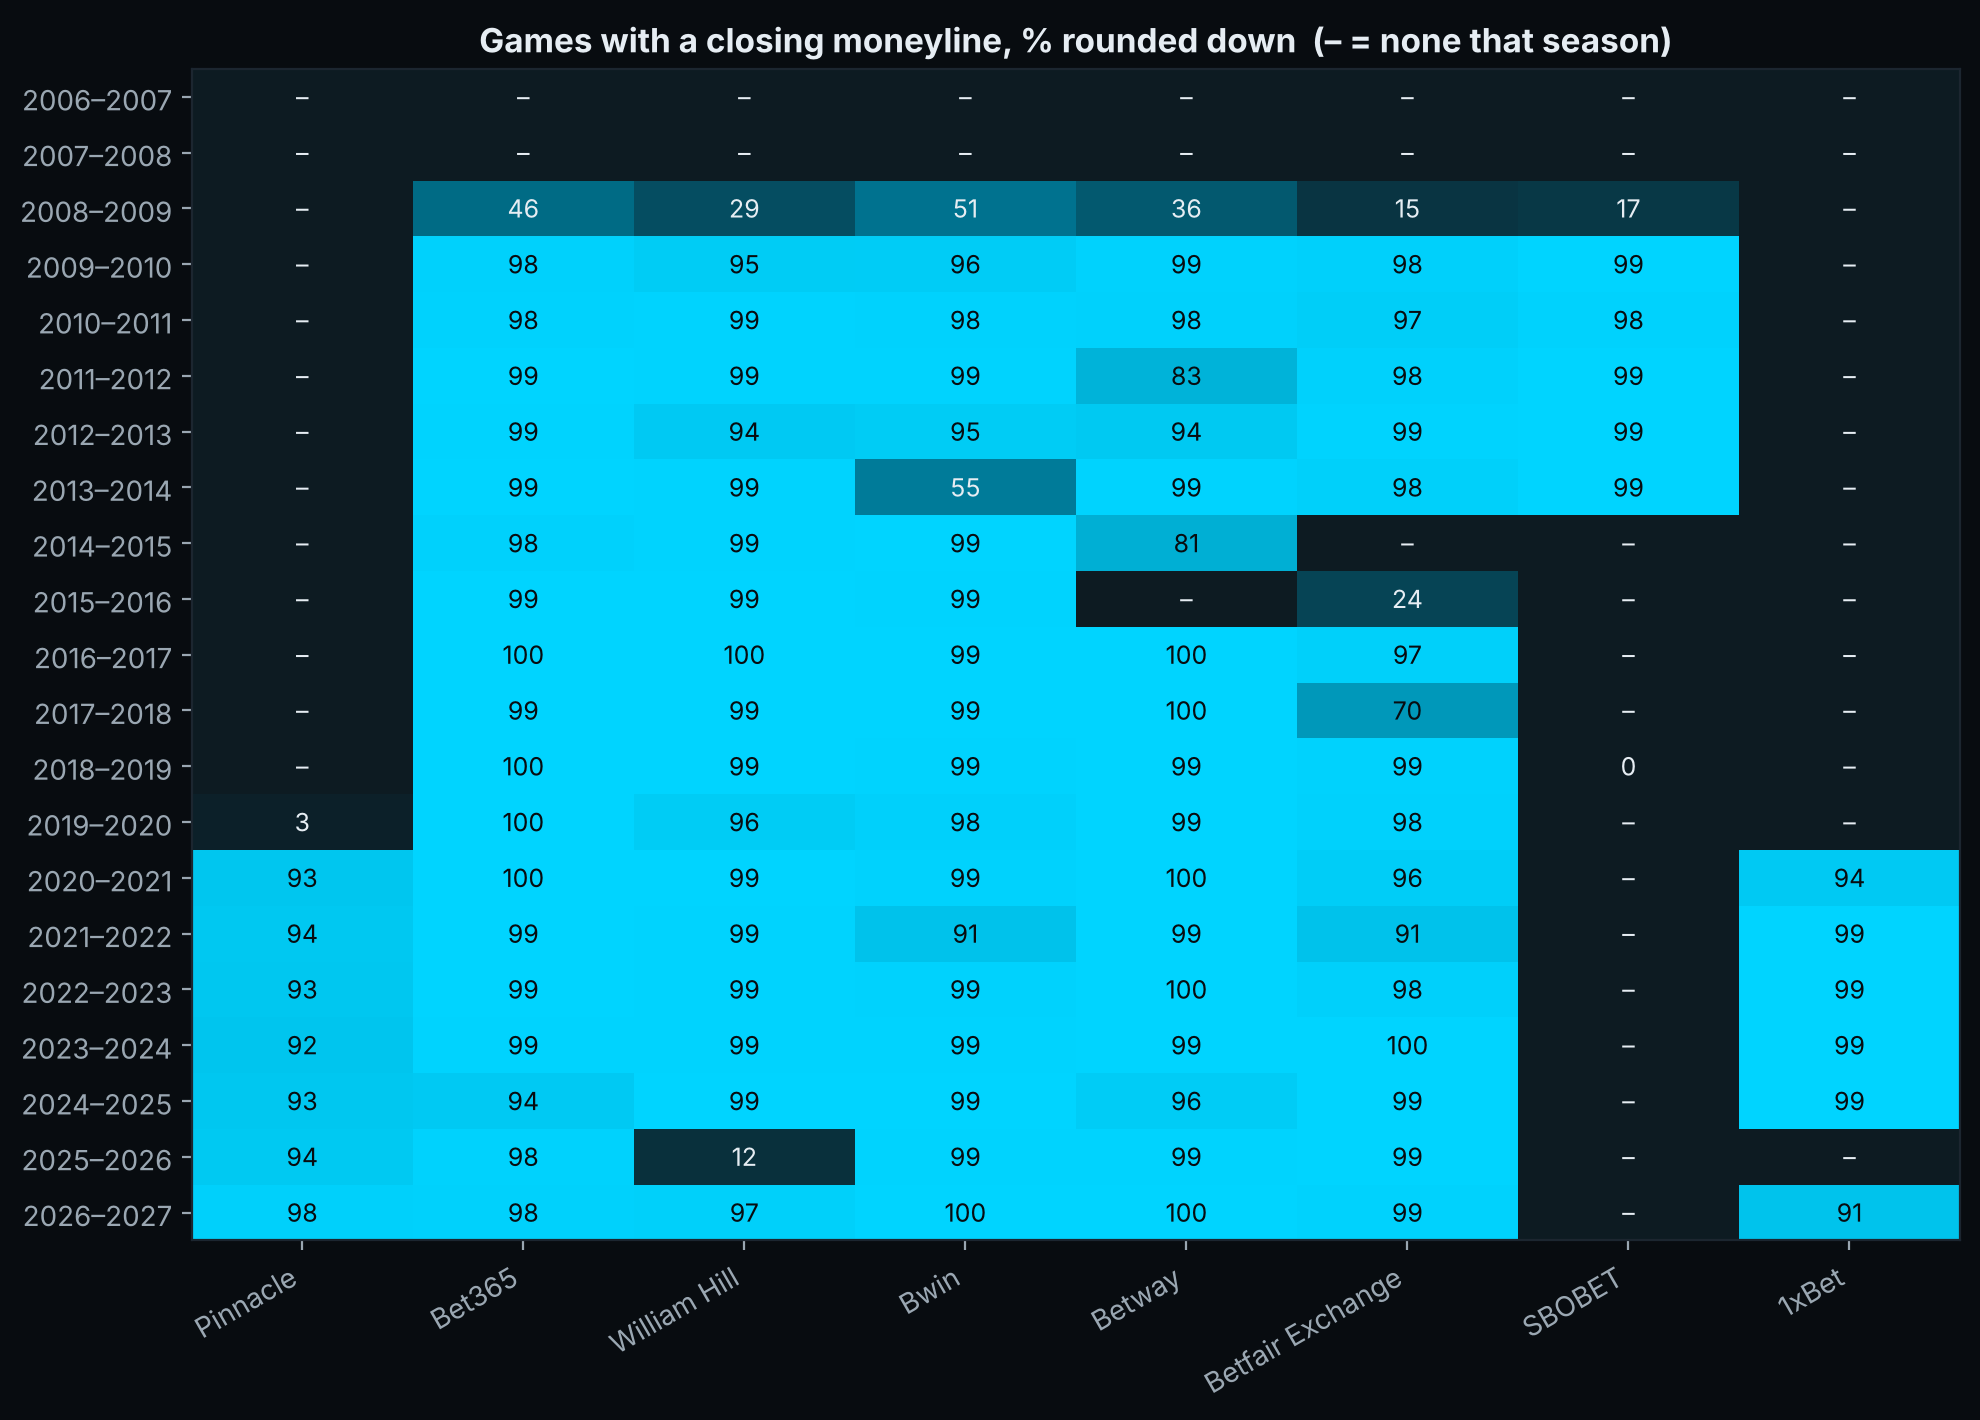

In [7]:
got = {b: DAY[priced(b)].min() for b in BOOKS}
check("first price, book by book, as listed: Bet365 and Bwin 4 Oct 2006 ... Pinnacle 1 Aug 2020", got == CLAIMS["first_price"],
      " · ".join(f"{NAME_OF.get(b, b)} {d}" for b, d in got.items()))
early = F["Season"] <= "2007/2008"
not_1x2 = [c for c in PRICES if c.split("_")[1] != "1X2"]
check("2006-07 and 2007-08 carry the 1X2 only; the moneyline starts in 2008-09",
      not F.loc[early, not_1x2].notna().any().any() and F.loc[early, [c for c in PRICES if "_1X2_" in c]].notna().any().any()
      and F.loc[F[[c for c in PRICES if "_ML_" in c]].notna().any(axis=1), "Season"].min() == "2008/2009")
bad = {}
for k, (a, z) in CLAIMS["market_days"].items():
    b, m = k.split()
    d = days(b, m)
    if d[0] != a or (z is not None and d[-1] != z):
        bad[k] = (d[0], d[-1])
check("first (and last) day of each market, as in the README: William Hill's moneyline from 17 Feb 2009 and 1X2 from 6 Oct 2006, "
      "Betway's 1X2 from 29 Sep 2007 and moneyline from 29 Jan 2009, Betfair Exchange's moneyline from 11 Feb 2009 and 1X2 from "
      "1 Dec 2007 to 11 Jun 2014, Bwin's regular-time total 6 Oct 2011 to 11 Mar 2020, SBOBET's 8 Oct 2014 to 16 Feb 2022, "
      "1xBet's moneyline from 20 Jan 2021", not bad, f"{bad}")
x1 = {m: days("1xBet", m)[0][:6] for m in CLAIMS["onexbet_october_2014"]}
check("1xBet's 1X2, puck line and regular-time total start in October 2014; no 1xBet moneyline in 2025-26",
      set(x1.values()) == {"201410"} and not priced("1xBet", "ML")[F["Season"] == "2025/2026"].any(), f"{x1}")

for (field, title), expected in CLAIMS["coverage"].items():
    books = list(next(iter(expected.values())).keys())
    got = {s: {b: share(int(x[f"{b}_{field}"].notna().sum()), len(x)) for b in books} for s, x in F.groupby("Season")}
    diff = [f"{s} {NAME_OF.get(b, b)} {got[s][b]} vs {expected.get(s, {}).get(b)}" for s in got for b in books if got[s][b] != expected.get(s, {}).get(b)]
    check(f"{title}: share of games, season by season, as in the README ({len(got)} seasons × {len(books)} books)",
          not diff and set(got) == set(expected), ", ".join(diff[:4]))

cov = pd.DataFrame({b: {s: x[f"{b}_ML_Home_Close"].notna().mean() * 100 for s, x in F.groupby("Season")} for b in BOOKS})
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(10, 7.2))
ax.imshow(cov.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=100)
ax.set_xticks(range(len(BOOKS)), [NAME_OF.get(b, b) for b in BOOKS], rotation=30, ha="right")
ax.set_yticks(range(len(cov)), [s.replace("/", "–") for s in cov.index])
ax.grid(False)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        v = cov.iat[i, j]
        ax.text(j, i, "–" if v == 0 else str(int(v)), ha="center", va="center", fontsize=9, color=BG if v > 60 else FG)
ax.set_title("Games with a closing moneyline, % rounded down  (– = none that season)")
plt.tight_layout(); plt.show()

## 5 · Opening, closing, start

The opening price is the first price recorded for the main line, the closing price the last one before the start.
The README sets hard limits and gives the median times; all recomputed here.

In [8]:
opens = [c for c in ODDS if c.endswith("_Open_Time")]
closes = [c for c in ODDS if c.endswith("_Close_Time")]
do = pd.concat([minutes_vs_start(c) for c in opens], axis=1)
dc = pd.concat([minutes_vs_start(c) for c in closes], axis=1)
check("no opening price is stamped after the scheduled start", do.max().max() <= 0, f"latest {do.max().max():.0f} min")
check(f"no opening price older than {CLAIMS['oldest_opening_days']} days", -do.min().min() <= CLAIMS["oldest_opening_days"] * 1440,
      f"oldest {-do.min().min() / 1440:.2f} days before")
after = sum(int((ts(o) >= ts(o.replace("_Open_", "_Close_"))).sum()) for o in opens)
check("an opening price is always recorded before the closing price of the same book and market", after == 0, f"{after}")
check(f"no closing price older than {CLAIMS['oldest_close_hours']} hours or stamped more than {CLAIMS['latest_close_minutes']} minutes after the start",
      -dc.min().min() <= 60 * CLAIMS["oldest_close_hours"] and dc.max().max() <= CLAIMS["latest_close_minutes"],
      f"oldest {-dc.min().min() / 60:.2f} h before, latest {dc.max().max():.1f} min after")
y18 = KICK >= pd.Timestamp("2018-01-01", tz="UTC")
every = pd.concat([minutes_vs_start(c) for c in closes if c.startswith("Pinnacle_")]
                  + [minutes_vs_start(c)[y18] for c in ("Bet365_PuckLine_Close_Time", "Bet365_Total_Close_Time")], axis=1)
check("Pinnacle's prices, and Bet365's puck line and total from 2018: closing price recorded between 12 hours before and 30 minutes after the start",
      -every.min().min() <= 60 * CLAIMS["every_change_close_hours"] and every.max().max() <= CLAIMS["latest_close_minutes"],
      f"oldest {-every.min().min() / 60:.2f} h before, latest {every.max().max():.1f} min after")
got = {b: {m: ("–" if f"{b}_{m}_Close_Time" not in F else short_age(minutes_vs_start(f"{b}_{m}_Close_Time").median()))
           for m in ("ML", "PuckLine", "Total", "RegTotal", "1X2")} for b in BOOKS}
check("median closing time against the scheduled start, book by book and market by market, as in the README",
      got == CLAIMS["median_close"], "" if got == CLAIMS["median_close"] else f"{got}")
age = {b: round(-minutes_vs_start(f"{b}_ML_Open_Time").median() / 60) for b in BOOKS}
check("median age of the opening moneyline at the scheduled start, as in the README", age == CLAIMS["median_open_age_h"],
      " · ".join(f"{NAME_OF.get(b, b)} {h} h" for b, h in age.items()))

def sec_share(cc, mask=None):
    v = pd.concat([RAW.loc[F.index if mask is None else mask, c] for c in cc]).dropna()
    return int((~v.str.endswith(":00Z")).sum()), len(v)
t_pin = [c for c in ODDS if c.startswith("Pinnacle_") and c.endswith("_Time")]
t_b365 = ["Bet365_PuckLine_Open_Time", "Bet365_PuckLine_Close_Time", "Bet365_Total_Open_Time", "Bet365_Total_Close_Time"]
t_1x = ["1xBet_ML_Open_Time", "1xBet_ML_Close_Time"]
z = F["Season"] == "2026/2027"
named = [sec_share(t_pin), sec_share(t_b365, y18), sec_share(t_1x, z)]
rest = 0; rest_n = 0
for c in [c for c in ODDS if c.endswith("_Time")]:
    v = RAW[c].copy()
    if c in t_pin: v[:] = np.nan
    if c in t_b365: v[y18] = np.nan
    if c in t_1x: v[z] = np.nan
    v = v.dropna(); rest += int((~v.str.endswith(":00Z")).sum()); rest_n += len(v)
check("times stamped to the minute (seconds 00), except Pinnacle's, Bet365's puck line and total from 2018 and 1xBet's 2026-27 moneyline, stamped to the second",
      all(s / n > 0.9 for s, n in named) and rest / rest_n < 0.0001,
      " · ".join(f"{s:,} of {n:,}" for s, n in named) + f" · all other times: {rest} of {rest_n:,} with seconds")
pd.DataFrame(got).T.rename(index=NAME_OF).rename_axis("Median closing time")

PASS  no opening price is stamped after the scheduled start   [latest -4 min]
PASS  no opening price older than 14 days   [oldest 13.99 days before]


PASS  an opening price is always recorded before the closing price of the same book and market   [0]
PASS  no closing price older than 36 hours or stamped more than 30 minutes after the start   [oldest 35.97 h before, latest 30.0 min after]
PASS  Pinnacle's prices, and Bet365's puck line and total from 2018: closing price recorded between 12 hours before and 30 minutes after the start   [oldest 11.97 h before, latest 30.0 min after]


PASS  median closing time against the scheduled start, book by book and market by market, as in the README
PASS  median age of the opening moneyline at the scheduled start, as in the README   [Pinnacle 29 h · Bet365 24 h · William Hill 27 h · Bwin 28 h · Betway 24 h · Betfair Exchange 24 h · SBOBET 24 h · 1xBet 64 h]
PASS  times stamped to the minute (seconds 00), except Pinnacle's, Bet365's puck line and total from 2018 and 1xBet's 2026-27 moneyline, stamped to the second   [45,740 of 46,956 · 43,933 of 44,693 · 427 of 427 · all other times: 8 of 471,577 with seconds]


,ML,PuckLine,Total,RegTotal,1X2
Median closing time,,,,,
Pinnacle,5 min after,5 min after,4 min after,–,–
Bet365,99 min before,1 min after,2 min after,–,2.1 h before
William Hill,3.2 h before,–,–,–,2.7 h before
Bwin,5.6 h before,–,–,6.7 h before,6.5 h before
Betway,96 min before,4.7 h before,40 min before,–,95 min before
Betfair Exchange,4 min before,–,–,–,3 min before
SBOBET,4.5 h before,–,–,2.6 h before,–
1xBet,22 min before,31 min before,–,34 min before,17 min before


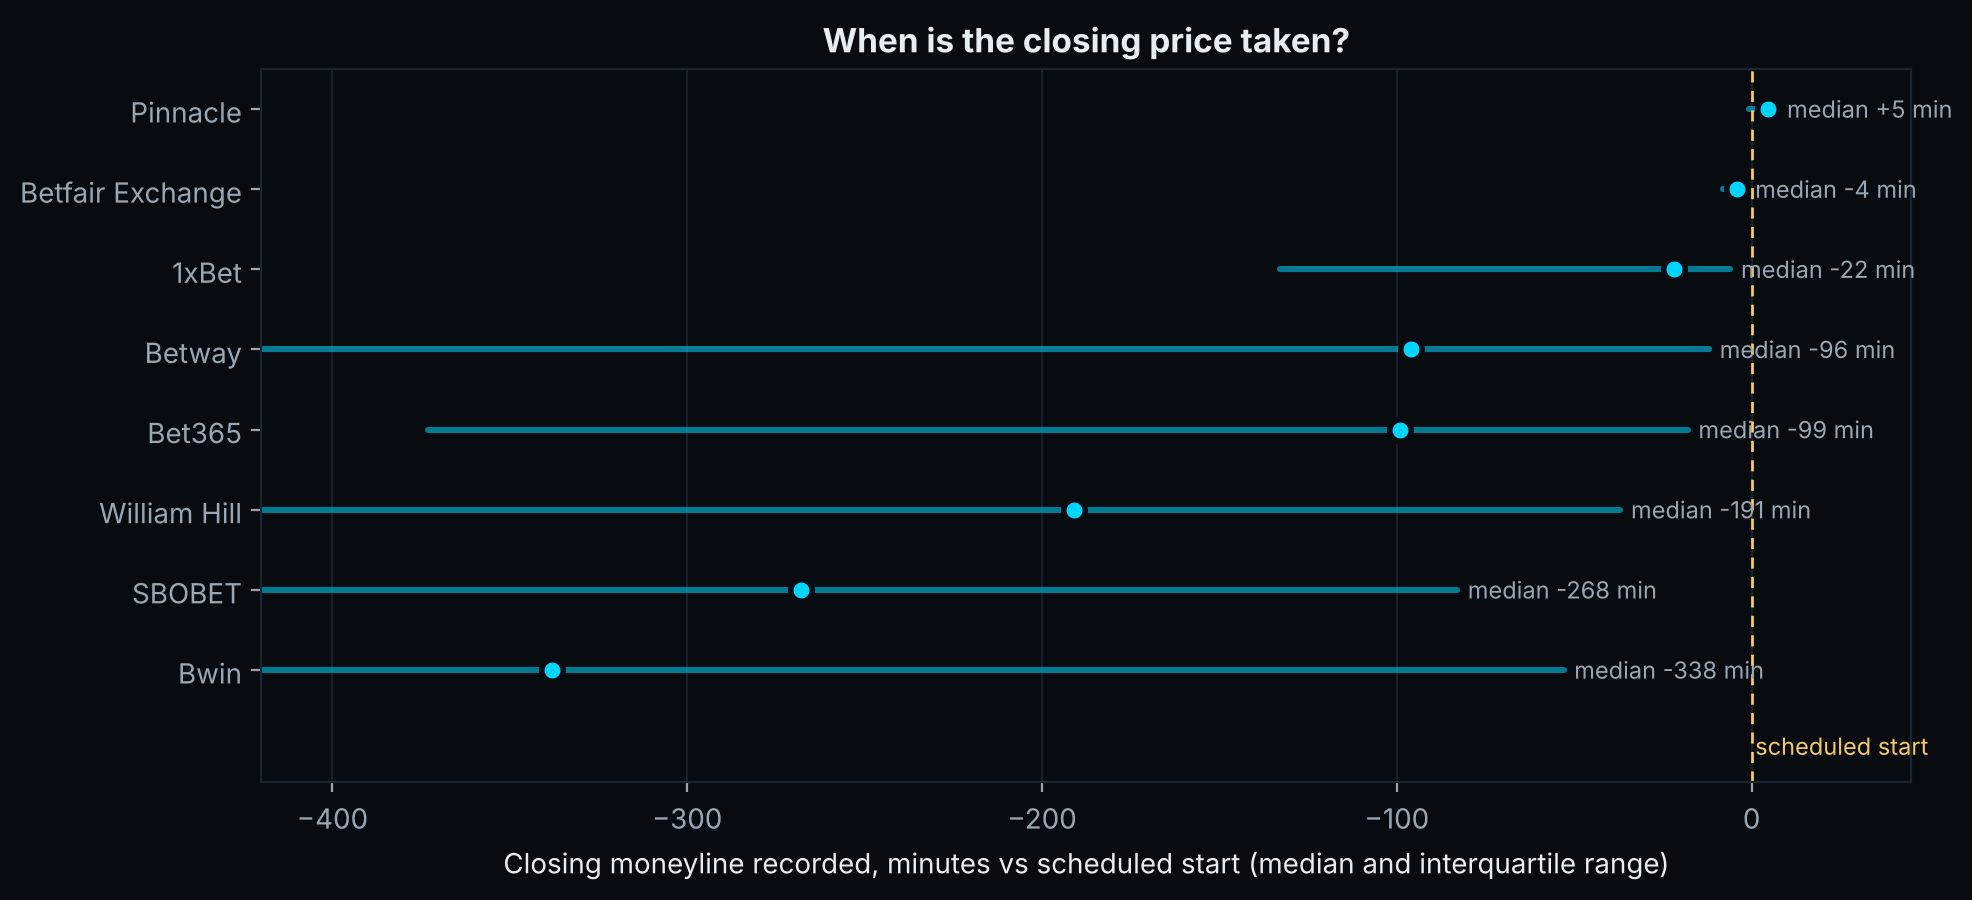

In [9]:
med = {b: minutes_vs_start(f"{b}_ML_Close_Time").dropna() for b in BOOKS}
order = sorted(BOOKS, key=lambda b: med[b].median())
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, b in enumerate(order):
    q1, q2, q3 = np.percentile(med[b], [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2.2, alpha=0.55, solid_capstyle="round")
    ax.scatter([q2], [i], s=60, color=CYAN, edgecolor=BG, linewidth=2, zorder=3)
    ax.text(max(q3, q2) + 3, i, f"median {q2:+.0f} min", va="center", fontsize=8.5, color=FG2)
ax.axvline(0, color=AMBER, linewidth=1, linestyle=(0, (4, 3)))
ax.text(1, -0.95, "scheduled start", color=AMBER, fontsize=8.5, va="center")
ax.set_ylim(-1.4, len(order) - 0.5)
ax.set_yticks(range(len(order)), [NAME_OF.get(b, b) for b in order])
ax.set_xlim(-420, 45); ax.grid(axis="y", visible=False)
ax.set_xlabel("Closing moneyline recorded, minutes vs scheduled start (median and interquartile range)")
ax.set_title("When is the closing price taken?")
plt.tight_layout(); plt.show()

## 6 · Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict the
winner better. Probabilities are de-margined proportionally; lower log-loss is better. Open and close are compared
**within a book**, on the games where the book has both. Then the two kinds of totals: each column's prices must
match its own definition, overtime included or regular time only.

In [10]:
home_won = (F["Winner"] == "Home").to_numpy()
rows = []
for b in BOOKS:
    o = F[[f"{b}_ML_Home_Open", f"{b}_ML_Away_Open"]].to_numpy(float)
    c = F[[f"{b}_ML_Home_Close", f"{b}_ML_Away_Close"]].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    if ok.sum() < 100:
        continue
    def logloss(p):
        p = np.clip(p, 1e-6, 1 - 1e-6)
        return -np.mean(np.where(home_won[ok], np.log(p), np.log(1 - p)))
    rows.append((NAME_OF.get(b, b), int(ok.sum()), logloss(no_vig(o[ok, 0], o[ok, 1])), logloss(no_vig(c[ok, 0], c[ok, 1]))))
LL = pd.DataFrame(rows, columns=["Book", "Games", "Log-loss open", "Log-loss close"]).set_index("Book")
check("the closing moneyline predicts the winner better than the opening one, at every book", (LL["Log-loss close"] < LL["Log-loss open"]).all())
mg = {b: 100 * ((1 / F[[f"{b}_ML_Home_Close", f"{b}_ML_Away_Close"]].dropna()).sum(axis=1) - 1).median() for b in ("BetfairExchange", "Pinnacle")}
check("median closing margin: Betfair Exchange 3.3%, above Pinnacle's 2.5% (consistent with prices net of the exchange's commission)",
      {b: f"{v:.1f}" for b, v in mg.items()} == CLAIMS["margin_close_median"], f"{mg['BetfairExchange']:.2f}% · {mg['Pinnacle']:.2f}%")
r60 = F["Home_Score_60"] + F["Away_Score_60"]
got = {}
for b, col in (("Pinnacle", "Total"), ("Bet365", "Total"), ("Bwin", "RegTotal"), ("Betway", "Total"), ("SBOBET", "RegTotal"), ("1xBet", "RegTotal")):
    ln, ov, un = F[f"{b}_{col}_Line_Close"], F[f"{b}_{col}_Over_Close"], F[f"{b}_{col}_Under_Close"]
    m = ln.isin([4.5, 6.5, 8.5]) & ov.notna() & un.notna()
    got[b] = {"Column": "Total" if col == "Total" else "Total (regular time)", "Games": f"{int(m.sum()):,}",
              "No-vig over": f"{100 * no_vig(ov[m], un[m]).mean():.1f}%", "Over final": f"{100 * (F['Total_Score'][m] > ln[m]).mean():.1f}%",
              "Over 60": f"{100 * (r60[m] > ln[m]).mean():.1f}%"}
check("each total column matches its own definition: on the 4.5, 6.5 and 8.5 closing lines, the books' over probability, the overs at "
      "the final score and after 60 minutes, as in the README's table", got == CLAIMS["totals_definition"], "" if got == CLAIMS["totals_definition"] else f"{got}")
fav = 0; n_pl = 0
for b in ("Pinnacle", "Bet365", "Betway", "1xBet"):
    for ph in ("Open", "Close"):
        ln = F[f"{b}_PuckLine_Home_Line_{ph}"]
        t_pl = ts(f"{b}_PuckLine_{ph}_Time")
        near = lambda bk: (ts(f"{bk}_ML_{ph}_Time") - t_pl).abs() <= pd.Timedelta(hours=3)
        own = np.where(near(b), no_vig(F[f"{b}_ML_Home_{ph}"], F[f"{b}_ML_Away_{ph}"]), np.nan)
        pin = np.where(near("Pinnacle"), no_vig(F[f"Pinnacle_ML_Home_{ph}"], F[f"Pinnacle_ML_Away_{ph}"]), np.nan)
        p_home = np.where(np.isnan(own), pin, own)
        giver = np.where(ln == -1.5, p_home, 1 - p_home)
        m = ln.notna() & ~np.isnan(p_home)
        n_pl += int(m.sum()); fav += int((m & (giver < CLAIMS["underdog_puckline_below"])).sum())
check("no puck line gives -1.5 to a clear underdog: below 0.42 at the same book's moneyline (or Pinnacle's), recorded within 3 hours of it",
      fav == 0, f"{fav} of {n_pl:,} puck lines with such a moneyline")
LL.style.format({"Games": "{:,}", "Log-loss open": "{:.4f}", "Log-loss close": "{:.4f}"})

PASS  the closing moneyline predicts the winner better than the opening one, at every book
PASS  median closing margin: Betfair Exchange 3.3%, above Pinnacle's 2.5% (consistent with prices net of the exchange's commission)   [3.35% · 2.54%]
PASS  each total column matches its own definition: on the 4.5, 6.5 and 8.5 closing lines, the books' over probability, the overs at the final score and after 60 minutes, as in the README's table


PASS  no puck line gives -1.5 to a clear underdog: below 0.42 at the same book's moneyline (or Pinnacle's), recorded within 3 hours of it   [0 of 53,103 puck lines with such a moneyline]


,Games,Log-loss open,Log-loss close
Book,,,
Pinnacle,"7,684",0.6610,0.6584
Bet365,"18,127",0.6699,0.6681
William Hill,"15,811",0.6685,0.6660
Bwin,"14,912",0.6697,0.6672
Betway,"14,741",0.6690,0.6669
Betfair Exchange,"3,388",0.6693,0.6666
SBOBET,"5,074",0.6763,0.6755
1xBet,"6,246",0.6616,0.6546


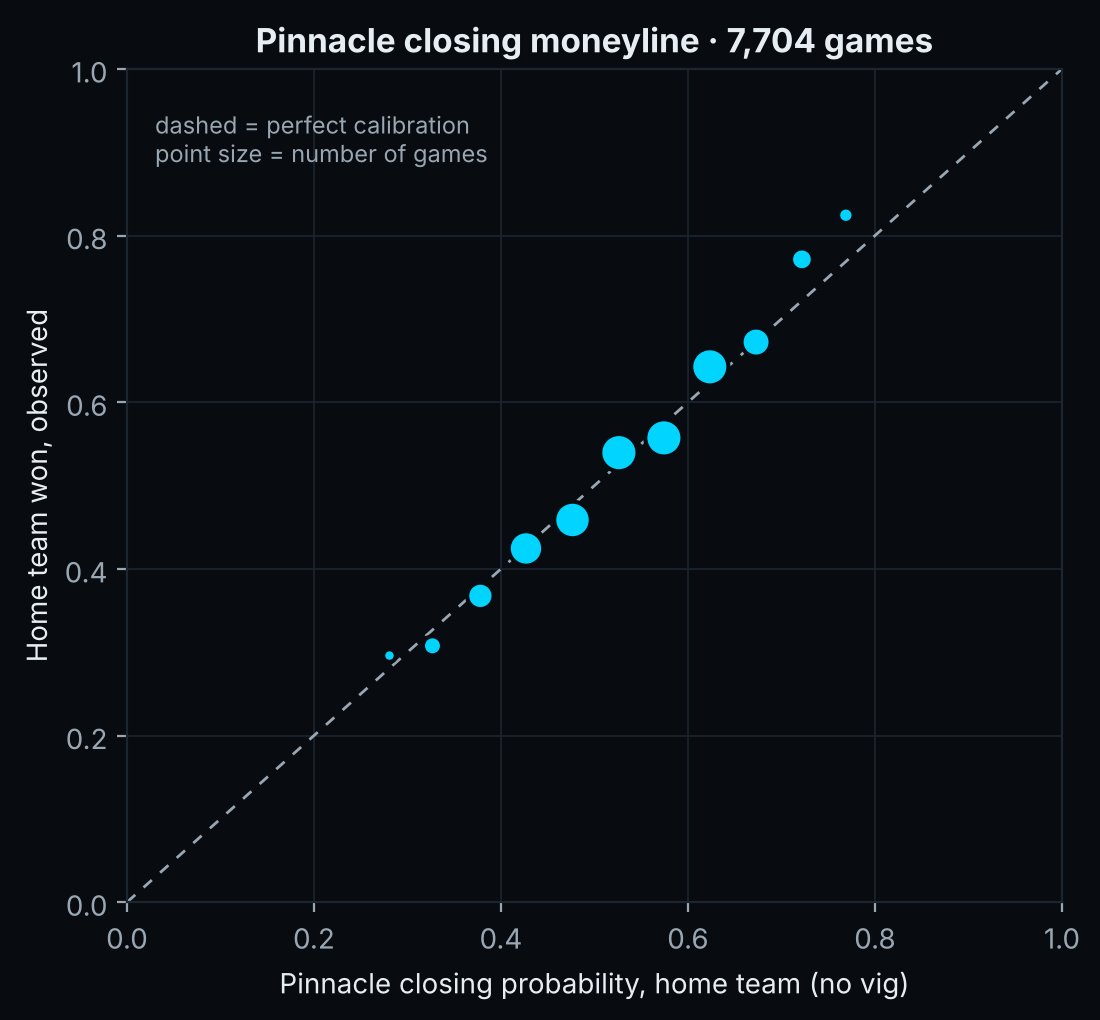

In [11]:
# Pinnacle closing moneyline: predicted probability of the home team vs observed frequency
c = F[["Pinnacle_ML_Home_Close", "Pinnacle_ML_Away_Close"]].to_numpy(float)
ok = ~np.isnan(c).any(1)
cal = pd.DataFrame({"p": no_vig(c[ok, 0], c[ok, 1]), "hit": home_won[ok]})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 40]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 6, 12, 180), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability, home team (no vig)"); ax.set_ylabel("Home team won, observed")
ax.set_title(f"Pinnacle closing moneyline · {ok.sum():,} games")
ax.text(0.03, 0.95, "dashed = perfect calibration\npoint size = number of games", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 7 · The games on the listing's images

The images of the Gumroad listing are drawn from the file. Their prices, times, scores and figures, recomputed.

In [12]:
IMAGES = {'file_1_seven_books_home_ml_close': {'20250604_FLA_EDM': ['1.8772', '1.83', '1.83', '1.8', '1.8', '1.86', '1.82'], '20250606_FLA_EDM': ['1.9615', '1.91', '1.91', '1.91', '1.83', '1.93', '1.91'], '20250609_EDM_FLA': ['1.7463', '1.71', '1.71', '1.67', '1.63', '1.7', '1.67'], '20250612_EDM_FLA': ['1.7812', '1.67', '1.67', '1.72', '1.67', '1.68', '1.58'], '20250614_FLA_EDM': ['1.9009', '1.91', '1.91', '1.87', '1.87', '1.94', '1.91'], '20250617_EDM_FLA': ['1.6494', '1.59', '1.57', '1.59', '1.63', '1.63', '1.66']}, 'file_2_one_game': {'game': '20261022_CAR_EDM', 'score_away_home': [5, 6], 'score_60': [5, 5], 'ending': 'Shootout', 'rows': {'Pinnacle': {'ml': ['1.7634', '2.18'], 'puckline': ['1.5', '1.463'], 'total': '6.5', 'total_regular_time': False, 'draw': ''}, 'Bet365': {'ml': ['1.71', '2.07'], 'puckline': ['1.5', '1.4348'], 'total': '', 'total_regular_time': False, 'draw': '4.25'}, 'WilliamHill': {'ml': ['1.73', '2.1'], 'puckline': ['', ''], 'total': '', 'total_regular_time': False, 'draw': '4'}, 'Bwin': {'ml': ['1.75', '2.15'], 'puckline': ['', ''], 'total': '', 'total_regular_time': False, 'draw': '4.1'}, 'Betway': {'ml': ['1.77', '2.1'], 'puckline': ['1.5', '1.48'], 'total': '6.5', 'total_regular_time': False, 'draw': '4.2'}, 'BetfairExchange': {'ml': ['1.76', '2.16'], 'puckline': ['', ''], 'total': '', 'total_regular_time': False, 'draw': ''}, '1xBet': {'ml': ['1.7519', '2.1'], 'puckline': ['1.5', '1.44'], 'total': '6.25', 'total_regular_time': True, 'draw': '4.31'}}}, 'cover_3_open_close_times': {'game': '20261011_CAR_PHI', 'score_away_home': [4, 1], 'rows': {'Pinnacle': ['1.5747', '2026-10-11T01:38:24Z', '1.4695', '2026-10-11T22:59:30Z'], 'Bet365': ['1.59', '2026-10-10T15:42:00Z', '1.4', '2026-10-11T23:00:00Z'], 'WilliamHill': ['1.73', '2026-10-10T15:09:00Z', '1.5', '2026-10-11T14:15:00Z'], 'Bwin': ['1.62', '2026-10-10T16:00:00Z', '1.44', '2026-10-11T22:52:00Z'], 'Betway': ['1.59', '2026-10-10T22:04:00Z', '1.44', '2026-10-11T22:59:00Z'], 'BetfairExchange': ['1.56', '2026-10-11T00:13:00Z', '1.47', '2026-10-11T22:52:00Z'], '1xBet': ['1.6803', '2026-10-10T07:44:07Z', '1.4902', '2026-10-11T22:59:30Z']}}, 'file_4_total_moves': {'date': '2026-10-31', 'rows': {'20261031_CHI_BOS': ['6', '6.5', '6.5', '6', '9', '8', 'Overtime'], '20261031_STL_DET': ['6', '5.5', '5.5', '5.5', '9', '9', 'Regulation'], '20261031_TBL_NSH': ['6', '6.5', '6.5', '6', '9', '8', 'Shootout'], '20261031_EDM_NYI': ['6.5', '6', '5.5', '5.75', '4', '4', 'Regulation'], '20261031_BUF_LAK': ['6', '6', '5.5', '5.75', '5', '5', 'Regulation'], '20261031_OTT_SJS': ['6.5', '6.5', '6.5', '6.25', '6', '6', 'Regulation'], '20261031_CBJ_DAL': ['6', '5.5', '5.5', '5.5', '4', '4', 'Regulation']}}, 'file_5_1x2_overtime': {'20260421_MTL_TBL': {'bwin': ['1.85', '4.1', '3.4'], 'draws': {'Bet365': '4.2', '1xBet': '4.52'}, 'score_away_home': [2, 3], 'ending': 'Overtime'}, '20260421_LAK_COL': {'bwin': ['1.57', '4.6', '4.4'], 'draws': {'Bet365': '4.5', '1xBet': '4.63'}, 'score_away_home': [1, 2], 'ending': 'Overtime'}, '20260422_DAL_MIN': {'bwin': ['2.2', '4.1', '2.6'], 'draws': {'Bet365': '4', '1xBet': '4.33'}, 'score_away_home': [4, 3], 'ending': 'Overtime'}, '20260424_TBL_MTL': {'bwin': ['2.6', '4.33', '2.35'], 'draws': {'Bet365': '4.1', '1xBet': '4.32'}, 'score_away_home': [2, 3], 'ending': 'Overtime'}, '20260425_DAL_MIN': {'bwin': ['2.3', '4.25', '2.7'], 'draws': {'Bet365': '4', '1xBet': '4.17'}, 'score_away_home': [2, 3], 'ending': 'Overtime'}}, 'sub_3_1x2_overtime': {'20261029_UTA_PIT': {'bwin': ['2.6', '4.1', '2.2'], 'draws': {'Betway': '4.25', '1xBet': '4.42'}, 'score_away_home': [4, 3], 'ending': 'Overtime'}, '20261029_NYI_MIN': {'bwin': ['1.83', '4.2', '3.4'], 'draws': {'Betway': '4.2', '1xBet': '4.43'}, 'score_away_home': [4, 3], 'ending': 'Overtime'}, '20261029_OTT_LAK': {'bwin': ['2.5', '4', '2.3'], 'draws': {'Betway': '4', '1xBet': '4.24'}, 'score_away_home': [5, 6], 'ending': 'Overtime'}, '20261031_CHI_BOS': {'bwin': ['1.67', '4.4', '3.9'], 'draws': {'Betway': '4.3', '1xBet': '4.61'}, 'score_away_home': [4, 5], 'ending': 'Overtime'}, '20261031_TBL_NSH': {'bwin': ['3.1', '4.2', '1.91'], 'draws': {'Betway': '4.2', '1xBet': '4.52'}, 'score_away_home': [4, 5], 'ending': 'Shootout'}}, 'file_6_exchange_vs_pinnacle': {'date': '2026-04-16', 'rows': {'20260416_STL_UTA': ['1.8475', '2026-04-16T23:29:57Z', '1.81', '2026-04-16T23:28:00Z'], '20260416_ANA_NSH': ['2.06', '2026-04-17T00:06:40Z', '2.06', '2026-04-16T23:58:00Z'], '20260416_SJS_WPG': ['1.6369', '2026-04-17T00:03:48Z', '1.62', '2026-04-16T23:58:00Z'], '20260416_LAK_CGY': ['2.5', '2026-04-17T01:02:19Z', '2.44', '2026-04-17T00:58:00Z'], '20260416_VAN_EDM': ['1.3067', '2026-04-17T00:58:57Z', '1.31', '2026-04-17T00:58:00Z']}}, 'file_7_coverage_ml_close': {'Pinnacle': {'first': '2019/2020', 'all_pct': 29.5, 'pct_2025_26': 94.3, 'pct_2026_27': 98.2}, 'Bet365': {'first': '2008/2009', 'all_pct': 86.6, 'pct_2025_26': 99.0, 'pct_2026_27': 98.7}, 'WilliamHill': {'first': '2008/2009', 'all_pct': 80.9, 'pct_2025_26': 12.6, 'pct_2026_27': 97.8}, 'Bwin': {'first': '2008/2009', 'all_pct': 84.0, 'pct_2025_26': 99.4, 'pct_2026_27': 100.0}, 'Betway': {'first': '2008/2009', 'all_pct': 79.3, 'pct_2025_26': 99.4, 'pct_2026_27': 100.0}, 'BetfairExchange': {'first': '2008/2009', 'all_pct': 73.8, 'pct_2025_26': 99.6, 'pct_2026_27': 99.1}, 'SBOBET': {'first': '2008/2009', 'all_pct': 24.1, 'pct_2025_26': 0.0, 'pct_2026_27': 0.0}, '1xBet': {'first': '2020/2021', 'all_pct': 25.7, 'pct_2025_26': 0.0, 'pct_2026_27': 91.6}}, 'file_8_tiles': {'games': 26079, 'seasons': 21, 'books': 8, 'prices': 1290732, 'columns': 194, 'stages': {'Regular Season': 24298, 'Playoffs': 1781}, 'endings': {'Regulation': 20073, 'Overtime': 3528, 'Shootout': 2478}, 'first_game': '20061004', 'last_game': '20261031'}, 'sub_1_home_ml_close': {'20261031_CHI_BOS': ['1.4329', '1.38', '1.44', '1.42', '1.44', '1.45', '1.4608'], '20261031_STL_DET': ['1.8929', '1.81', '1.91', '1.87', '1.87', '1.89', '1.8772'], '20261031_TBL_NSH': ['2.57', '2.44', '2.38', '2.5', '2.4', '2.52', '2.46'], '20261031_EDM_NYI': ['1.9434', '1.86', '1.91', '1.91', '1.91', '1.95', '1.9091'], '20261031_BUF_LAK': ['2.17', '2.1', '2.1', '2.15', '2.1', '2.18', '2.11']}, 'sub_4_books_2026_27': {'games': 226, 'min_close_ml_pct': 91, 'books': ['Pinnacle', 'Bet365', 'WilliamHill', 'Bwin', 'Betway', 'BetfairExchange', '1xBet']}}
R = RAW.fillna("").set_index("Game_ID")
B7 = [b for b in BOOKS if b != "SBOBET"]
x = IMAGES["file_1_seven_books_home_ml_close"]
check("image 1: the 2025 Stanley Cup Final, games 1-6, home closing moneyline at the seven books",
      all([R.loc[g, f"{b}_ML_Home_Close"] for b in B7] == v for g, v in x.items())
      and list(x) == F.loc[(F["Season"] == "2024/2025") & (F["Stage"] == "Playoffs") & (RAW["NHL_Game_ID"].str[6:8] == "04"), "Game_ID"].tolist())
x = IMAGES["file_2_one_game"]; r = R.loc[x["game"]]
ok = [int(r["Away_Score"]), int(r["Home_Score"])] == x["score_away_home"] and [int(r["Away_Score_60"]), int(r["Home_Score_60"])] == x["score_60"]
ok &= r["Match_Ending"] == x["ending"] == "Shootout" and r["Result_60"] == "Draw"
for b, v in x["rows"].items():
    tot_col = f"{b}_RegTotal_Line_Close" if v["total_regular_time"] else f"{b}_Total_Line_Close"
    ok &= [r[f"{b}_ML_Away_Close"], r[f"{b}_ML_Home_Close"]] == v["ml"]
    ok &= [r.get(f"{b}_PuckLine_Home_Line_Close", ""), r.get(f"{b}_PuckLine_Home_Close", "")] == v["puckline"]
    ok &= r.get(tot_col, "") == v["total"] and r.get(f"{b}_1X2_Draw_Close", "") == v["draw"]
check("image 2: Hurricanes at Oilers, 22 Oct 2026: closing moneyline, puck line, totals and 1X2 draw at seven books; 5-5 after 60 minutes, 6-5 in a shootout", ok)
x = IMAGES["cover_3_open_close_times"]; r = R.loc[x["game"]]
check("image 3: Hurricanes at Flyers, 11 Oct 2026: Carolina's opening and closing moneyline with their times at seven books, every one shorter at the close",
      all([r[f"{b}_ML_Away_Open"], r[f"{b}_ML_Open_Time"], r[f"{b}_ML_Away_Close"], r[f"{b}_ML_Close_Time"]] == v and float(v[2]) < float(v[0])
          for b, v in x["rows"].items()) and [int(r["Away_Score"]), int(r["Home_Score"])] == x["score_away_home"])
x = IMAGES["file_4_total_moves"]
check("image 4: 31 Oct 2026, the total from Pinnacle's open to the close, Betway and 1xBet (regular time) at the close, goals",
      all([R.loc[g, c] for c in ("Pinnacle_Total_Line_Open", "Pinnacle_Total_Line_Close", "Betway_Total_Line_Close", "1xBet_RegTotal_Line_Close", "Total_Score")]
          + [str(int(R.loc[g, "Home_Score_60"]) + int(R.loc[g, "Away_Score_60"])), R.loc[g, "Match_Ending"]] == v for g, v in x["rows"].items()))
for key, label in (("file_5_1x2_overtime", "image 5: five 2026 first-round games that went to overtime"), ("sub_3_1x2_overtime", "subscription image 3: five 2026-27 games that went past 60 minutes")):
    x = IMAGES[key]
    check(label + ": Bwin's 1X2 and two other books' draw at the close, tied after 60 minutes",
          all([R.loc[g, f"Bwin_1X2_{s}_Close"] for s in ("Home", "Draw", "Away")] == v["bwin"]
              and all(R.loc[g, f"{b}_1X2_Draw_Close"] == p for b, p in v["draws"].items())
              and [int(R.loc[g, "Away_Score"]), int(R.loc[g, "Home_Score"])] == v["score_away_home"]
              and R.loc[g, "Match_Ending"] == v["ending"] != "Regulation" and R.loc[g, "Result_60"] == "Draw" for g, v in x.items()))
x = IMAGES["file_6_exchange_vs_pinnacle"]
check("image 6: 16 Apr 2026, Pinnacle and Betfair Exchange at the close, with their times",
      all([R.loc[g, c] for c in ("Pinnacle_ML_Home_Close", "Pinnacle_ML_Close_Time", "BetfairExchange_ML_Home_Close", "BetfairExchange_ML_Close_Time")] == v
          for g, v in x["rows"].items()))
x = IMAGES["file_7_coverage_ml_close"]
y25, y26 = F["Season"] == "2025/2026", F["Season"] == "2026/2027"
got = {b: {"first": F.loc[F[f"{b}_ML_Home_Close"].notna(), "Season"].min(), "all_pct": round(100 * F[f"{b}_ML_Home_Close"].notna().mean(), 1),
           "pct_2025_26": round(100 * F.loc[y25, f"{b}_ML_Home_Close"].notna().mean(), 1), "pct_2026_27": round(100 * F.loc[y26, f"{b}_ML_Home_Close"].notna().mean(), 1)}
       for b in BOOKS}
check("image 7: first season with a closing moneyline and share of games with one, all games, 2025-26 and 2026-27", got == x,
      " · ".join(f"{NAME_OF.get(b, b)} {v['all_pct']}%" for b, v in got.items()))
x = IMAGES["file_8_tiles"]
check("image 8: 26,079 games · 21 seasons · 8 books · 1,290,732 prices · 194 columns, stages and endings",
      (x["games"], x["seasons"], x["books"], x["prices"], x["columns"]) == (len(F), F["Season"].nunique(), len(BOOKS), len(cells), F.shape[1])
      and x["stages"] == F["Stage"].value_counts().to_dict() and x["endings"] == F["Match_Ending"].value_counts().to_dict()
      and (x["first_game"], x["last_game"]) == (DAY.min(), DAY.max()))
x = IMAGES["sub_1_home_ml_close"]
check("subscription image 1: 31 Oct 2026, home closing moneyline at the seven books",
      all([R.loc[g, f"{b}_ML_Home_Close"] for b in B7] == v for g, v in x.items()))
x = IMAGES["sub_4_books_2026_27"]
m27 = min(100 * F.loc[y26, f"{b}_ML_Home_Close"].notna().mean() for b in x["books"])
check("subscription image 4: in 2026-27, seven books each close the moneyline on at least 91% of the 226 games",
      x["games"] == int(y26.sum()) and int(m27) == x["min_close_ml_pct"] and x["books"] == B7, f"{m27:.1f}%")

PASS  image 1: the 2025 Stanley Cup Final, games 1-6, home closing moneyline at the seven books
PASS  image 2: Hurricanes at Oilers, 22 Oct 2026: closing moneyline, puck line, totals and 1X2 draw at seven books; 5-5 after 60 minutes, 6-5 in a shootout
PASS  image 3: Hurricanes at Flyers, 11 Oct 2026: Carolina's opening and closing moneyline with their times at seven books, every one shorter at the close
PASS  image 4: 31 Oct 2026, the total from Pinnacle's open to the close, Betway and 1xBet (regular time) at the close, goals
PASS  image 5: five 2026 first-round games that went to overtime: Bwin's 1X2 and two other books' draw at the close, tied after 60 minutes
PASS  subscription image 3: five 2026-27 games that went past 60 minutes: Bwin's 1X2 and two other books' draw at the close, tied after 60 minutes
PASS  image 6: 16 Apr 2026, Pinnacle and Betfair Exchange at the close, with their times
PASS  image 7: first season with a closing moneyline and share of games with one, all games, 

## 8 · Said plainly, checked

The limits the listing and the README state up front, recomputed.

In [13]:
empty = F[PRICES].isna().all(axis=1)
nov07 = (DAY >= "20071101") & (DAY <= "20071128")
rest = empty & ~nov07
late06 = (DAY >= "20061101") & (DAY <= "20061231")
check("232 games without any price: 174 of the 185 games of 1-28 Nov 2007, most of the others in Nov-Dec 2006",
      empty.sum() == CLAIMS["no_price_games"] and (int((empty & nov07).sum()), int(nov07.sum())) == CLAIMS["no_price_nov_2007"]
      and (rest & late06).sum() > rest.sum() / 2, f"{int(empty.sum())} · {int((empty & nov07).sum())} of {int(nov07.sum())} · {int((rest & late06).sum())} of the other {int(rest.sum())} in Nov-Dec 2006")
pin = priced("Pinnacle")
check("Pinnacle starts on 1 Aug 2020, with the 2020 playoffs: no Pinnacle price before",
      DAY[pin].min() == CLAIMS["pinnacle_first"] and F.loc[pin & (F["Season"] == "2019/2020"), "Stage"].eq("Playoffs").all())
post = DAY >= CLAIMS["pinnacle_first"]
ml_pin = F["Pinnacle_ML_Home_Close"].notna() | F["Pinnacle_ML_Home_Open"].notna()
nopin = post & ~ml_pin
ari, uhc = team("Arizona Coyotes"), team("Utah Hockey Club")
bubble = nopin & ~ari & (F["Season"] == "2019/2020")
split = {"Arizona": int((nopin & ari).sum()), "Utah HC 2024-25": int((nopin & uhc).sum()), "2020 playoffs": int(bubble.sum()),
         "others": int((nopin & ~ari & ~uhc & ~bubble).sum())}
check("from Aug 2020, 469 games without a Pinnacle moneyline: all 311 Arizona games, all 82 Utah Hockey Club games of 2024-25, 61 of the 2020 playoffs, 15 others",
      nopin.sum() == CLAIMS["no_pinnacle_ml"] and split == CLAIMS["no_pinnacle_ml_split"]
      and (nopin & ari).sum() == (ari & post).sum() and (nopin & uhc).sum() == uhc.sum(), f"{split}")
nb = CLAIMS["no_pinnacle_ml_but"]
got = {"total": int((nopin & priced("Pinnacle", "Total")).sum()), "puck line": int((nopin & priced("Pinnacle", "PuckLine")).sum()),
       "closing total": int((nopin & F["Pinnacle_Total_Over_Close"].notna()).sum()),
       "closing puck line": int((nopin & F["Pinnacle_PuckLine_Home_Close"].notna()).sum()), "no price": int((nopin & ~pin).sum())}
check("on these games, Pinnacle has a total on 309 and a puck line on 145 (48 closing totals, 19 closing puck lines); 145 have no Pinnacle price at all",
      got == nb, f"{got}")
b3 = CLAIMS["bet365_pl_total"]
ps = {m: F.loc[priced("Bet365", m), "Season"].value_counts() for m in ("PuckLine", "Total")}
s13 = F["Season"] == "2012/2013"
pct13 = (int(100 * F.loc[s13, "Bet365_PuckLine_Home_Close"].notna().mean()), int(100 * F.loc[s13, "Bet365_Total_Over_Close"].notna().mean()))
from_ = {m: DAY[priced("Bet365", m) & (F["Season"] >= "2017/2018")].min() for m in ("PuckLine", "Total")}
cont = all(ps[m].get(s, 0) > 0.9 * (F["Season"] == s).sum() for m in ("PuckLine",) for s in SEASONS if "2018/2019" <= s <= "2025/2026")
cont &= all(ps["Total"].get(s, 0) > 0.9 * (F["Season"] == s).sum() for s in SEASONS if "2018/2019" <= s <= "2025/2026")
gap = all(ps[m].get(s, 0) == 0 for m in ps for s in ("2013/2014", "2014/2015", "2015/2016", "2016/2017"))
few = all(1 <= ps[m].get(s, 0) <= 10 for m in ps for s in ("2010/2011", "2011/2012"))
z = F["Season"] == "2026/2027"
c27 = (int(F.loc[z, "Bet365_PuckLine_Home_Close"].notna().sum()), int(F.loc[z, "Bet365_Total_Over_Close"].notna().sum()))
check("Bet365's puck line and total: 2008-09 and 2009-10, a handful of games in 2010-11 and 2011-12, part of 2012-13 (21% and 8%), "
      "then every season from 31 Dec 2017; in 2026-27, its closing puck line on 203 games and its closing total on 2",
      pct13 == b3["2012/2013"] and set(from_.values()) == {b3["from"]} and cont and gap and few and c27 == b3["2026/2027 closing"]
      and all(ps[m].get(s, 0) > 500 for m in ps for s in ("2008/2009", "2009/2010")), f"2012-13 {pct13} · from {from_} · 2026-27 {c27}")
y = F["Season"] == "2025/2026"
wh = DAY[priced("WilliamHill") & y]
check("William Hill: absent from the start of 2025-26 to 31 Mar 2026, back from 1 Apr 2026", wh.min() == CLAIMS["william_hill_back"], f"first 2025-26 price {wh.min()}")
bad = {}
for b, (a, z_) in CLAIMS["ml_gaps"].items():
    d = pd.Series(days(b, "ML"))
    inside = d.between(a, z_).any()
    before = (pd.Timestamp(a) - pd.Timestamp(d[d < a].max())).days == 1
    after_ = (pd.Timestamp(d[d > z_].min()) - pd.Timestamp(z_)).days == 1
    if inside or not before or not after_:
        bad[b] = (d[d < a].max(), d[d > z_].min())
check("moneyline gaps: Bwin 30 Jan to 7 Oct 2014, Betway 23 Mar 2015 to 11 Oct 2016, Betfair Exchange 12 Jun 2014 to 29 Feb 2016, "
      "William Hill 18 Jun 2025 to 31 Mar 2026 (prices on the day before and the day after each gap)", not bad, f"{bad}")
a, z_, n_after = CLAIMS["sbobet_ml"]
d = pd.Series(days("SBOBET", "ML"))
after_games = int((priced("SBOBET", "ML") & (DAY > z_)).sum())
check("SBOBET: moneyline from 19 Mar 2009 to 13 Jun 2014, then on 5 games; no puck line",
      d.iloc[0] == a and d[d <= z_].max() == z_ and after_games == n_after and (d[d > z_].min() > "20150101")
      and not any("SBOBET_PuckLine" in c for c in ODDS), f"{after_games} games after 13 Jun 2014")
bw = CLAIMS["betway_pl_total"]
pl = F.loc[priced("Betway", "PuckLine"), "Season"].value_counts(); to = F.loc[priced("Betway", "Total"), "Season"].value_counts()
s11 = F["Season"] == "2010/2011"
ok_bw = (all(pl.get(s, 0) > 0 for s in ("2008/2009", "2009/2010", "2010/2011", "2011/2012")) and pl.get("2012/2013", 0) == bw["pl_one_game_2012_13"]
         and all(pl.get(s, 0) == 0 for s in SEASONS if "2013/2014" <= s <= "2023/2024") and DAY[priced("Betway", "PuckLine") & (DAY > "20140101")].min() == bw["pl_back"]
         and all(to.get(s, 0) > 0 for s in ("2008/2009", "2009/2010")) and int(100 * to.get("2010/2011", 0) / s11.sum()) == bw["total_2010_11_pct"]
         and all(to.get(s, 0) == 0 for s in SEASONS if "2011/2012" <= s <= "2023/2024") and DAY[priced("Betway", "Total") & (DAY > "20140101")].min() == bw["total_back"])
check("Betway: puck line 2008-09 to 2011-12 (then one game in 2012-13), back from 15 Nov 2024; total 2008-09 and 2009-10 (then 6% of 2010-11), back from 14 Dec 2024", ok_bw)
check("the 2026-27 season stops on 31 Oct 2026: 226 games", z.sum() == CLAIMS["games_2026_27"] and DAY[z].max() == CLAIMS["last_day"])

PASS  232 games without any price: 174 of the 185 games of 1-28 Nov 2007, most of the others in Nov-Dec 2006   [232 · 174 of 185 · 38 of the other 58 in Nov-Dec 2006]
PASS  Pinnacle starts on 1 Aug 2020, with the 2020 playoffs: no Pinnacle price before
PASS  from Aug 2020, 469 games without a Pinnacle moneyline: all 311 Arizona games, all 82 Utah Hockey Club games of 2024-25, 61 of the 2020 playoffs, 15 others   [{'Arizona': 311, 'Utah HC 2024-25': 82, '2020 playoffs': 61, 'others': 15}]
PASS  on these games, Pinnacle has a total on 309 and a puck line on 145 (48 closing totals, 19 closing puck lines); 145 have no Pinnacle price at all   [{'total': 309, 'puck line': 145, 'closing total': 48, 'closing puck line': 19, 'no price': 145}]
PASS  Bet365's puck line and total: 2008-09 and 2009-10, a handful of games in 2010-11 and 2011-12, part of 2012-13 (21% and 8%), then every season from 31 Dec 2017; in 2026-27, its closing puck line on 203 games and its closing total on 2   [2012-13 (21, 

## 9 · Summary

In [14]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} PASS / {(~summary['Pass']).sum()} FAIL out of {len(summary)} claims")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

73 PASS / 0 FAIL out of 73 claims


Result,Claim,Detail
PASS,"26,079 games, one row each: Game_ID and NHL_Game_ID unique","26,079"
PASS,"194 columns: 18 for the game, then the books",194
PASS,"8 books, in this order: Pinnacle, Bet365, William Hill, Bwin, Betway, Betfair Exchange, SBOBET, 1xBet","Pinnacle, Bet365, WilliamHill, Bwin, Betway, BetfairExchange, SBOBET, 1xBet"
PASS,"for each book, its opening columns come first, then its closing columns",
PASS,"columns per book, as in the README: Pinnacle 22, Bet365 30, William Hill 14, Bwin 22, Betway 30, Betfair Exchange 14, SBOBET 14, 1xBet 30",Pinnacle 22 · Bet365 30 · William Hill 14 · Bwin 22 · Betway 30 · Betfair Exchange 14 · SBOBET 14 · 1xBet 30
PASS,"markets per book, as in the README (Total = overtime included, RegTotal = regular time)","{'Pinnacle': 'ML PuckLine Total', 'Bet365': 'ML PuckLine Total 1X2', 'WilliamHill': 'ML 1X2', 'Bwin': 'ML RegTotal 1X2', 'Betway': 'ML PuckLine Total 1X2', 'BetfairExchange': 'ML 1X2', 'SBOBET': 'ML RegTotal', '1xBet': 'ML PuckLine RegTotal 1X2'}"
PASS,"1,290,732 prices","1,290,732"
PASS,"every price is a decimal price of at least 1.01, with up to 4 decimals","lowest 1.14, highest 21.0"
PASS,every price comes with the time it was recorded,0 without a time
PASS,"every time is ISO 8601 in UTC, with the T and the Z","589,732 cells"


---

Everything above ran on the file a buyer downloads. The README in the ZIP holds the full column dictionary, the
coverage of every book season by season, how each price was checked, and every known limitation.

👉 🏒 **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/jytwci?utm_source=github&utm_medium=notebook&utm_campaign=nhl_world&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/nhl-opening-closing-odds-pinnacle-7-world-books-2006-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nhl_world&utm_content=whop_bottom) 👈

Games after 31 October 2026: the **[NHL World Books monthly updates](https://sportsdataolivier.gumroad.com/l/dhlawd?utm_source=github&utm_medium=notebook&utm_campaign=nhl_world&utm_content=notebook_monthly)** add each month's games, same 194 columns.

Licence: single commercial user. Use the data as you wish, including the models, predictions and products you sell.
Redistribution and resale of the files, or of the raw data in another format, are not permitted.
A question, an invoice or a custom extract: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*